# New attempts: missing data, survival, geography and maximum entropy

*Auxiliary notebook to [`ceramic_network_inference.ipynb`](ceramic_network_inference.ipynb). It holds new experiments with their theory, and two sections moved out of the main notebook: survival and selection (formerly Section 8, here Part 2) and Maximum Caliber (formerly Section 11, here Part 3).*

**The question.** *Which community made this pot, and what is missing from its production sequence?*

**Why the topic models stall.** With whole sites held out, LDA and the hSBM classify about half of the vessels correctly (four BoKs). Bootstrapping cannot lift this. A pseudo-document is made of the same 276 vessels, so it repeats old information rather than adding new; and pooling vessels of one label slips that label into an "unsupervised" model (main notebook, 7.1). To do better we need a better model of how the data were damaged, or new information. This notebook tries both.

**One picture for everything.**
$$C\;\xrightarrow{\;T_C\;}\;X\;\xrightarrow{\;s\;}\;S\;\xrightarrow{\;\sigma\;}\;Y\qquad(+\text{ find spot, form, context}).$$
A community $C$ makes a pot by a chain of techniques $X$, a Markov chain with kernel $T_C$. The pot is deposited, survives and is excavated ($S=1$) with probability $s$. On a surviving pot each step $v$ can still be recognised with probability $\sigma_v$; the recorded chain $Y$ is the subsequence that remains. We see $Y$ — with the find spot, form and context — only when $S=1$. Attribution is $p(C\mid Y,\dots,S=1)$; "what is missing" is $p(X\mid Y,\dots)$.

**Plan.**
1. Setup — the data and the LDA of the main notebook.
2. Lost pots: survival and selection, $P(X\mid S=1)$ *(moved from the main notebook)*.
3. Maximum Caliber *(moved from the main notebook)*.
4. Lost steps: the deletion channel — the hidden Markov model "chain as made → chain that survived". What it identifies, survival per site by EM, and the missing steps of a given pot.
5. Geography.
6. The bridge: one maximum-entropy family for practice, survival and attribution, and a classifier that uses all the evidence.
7. Answers.

**Results** (sites held out, 3 × 5-fold cross-validation, unless stated)
- **Lost pots.** Survival that depends on the chain cancels from attribution (proved), so it cannot raise the best accuracy, and survivors alone cannot identify it. *Using* the selection does help: with the find context as a prior, LDA rises from 0.51 to 0.77.
- **Lost steps.** The surviving chain is again a Markov chain, with kernel $K=(I-PD)^{-1}PS$ (proved; checked to $10^{-16}$ and by simulation). The original practice can be recovered only if the survival is known, because "nothing was lost" always fits.
  - When held-out pots are eroded (fragile steps kept with probability ≤ 0.5), modelling the erosion raises accuracy by 3–5 points and lowers the log-loss.
  - An erased step is found, in the right gap and as the right technique, at the first guess for 59 % of pots and within three guesses for 84 %.
- **Sites differ.** Take one practice per community and one survival rate per site; EM then finds sites with fewer fragile steps than that practice predicts:
  - among the middle-FBW megaliths (p = 0.01);
  - between Corded Ware flat graves and barrows (p = 0.005);
  - not in early or late FBW.

  Erosion and a local habit of decorating less fit these records equally well; only data on preservation can separate them.
- **Geography.** Within a community, chains do not grow more different with distance (no Mantel signal), so place and chain are separate evidence. Place alone gives 0.58; place combined with the Markov chain gives 0.64.
- **The bridge.** Markov attribution is exactly a log-linear (maximum-entropy) model in the transition counts (proved; checked to $10^{-16}$). Survival acts on it as one common "force", which cancels from attribution. A maximum-entropy classifier using transitions, geography and form reaches 0.69 with the best-calibrated probabilities of all models without find context (log-loss 0.82). Adding the find context gives 0.77, with a circularity caveat.

## 1 · Setup
The data, the held-out sites of Section 3 and the LDA of Section 4 of the main notebook: same functions, same seed, hence the same numbers.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", message="unrecognized keyword arguments")  # graph-tool

from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.special import logsumexp
from scipy.stats import chi2_contingency, chisquare, norm, spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from chaine import data, markov, maxcal
from chaine import topic_model as tm, classifiers as clf, evaluation as ev, plotting as pl
from chaine.data import BOKS, START, END

pl.setup()
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 110)
SEED = 0

def softmax_rows(L):
    """Row-wise softmax of log-scores, computed stably."""
    return np.exp(L - logsumexp(L, axis=1, keepdims=True))

In [2]:
df = data.load_vessels()
grammar = data.load_grammar(extra_chains=df["steps"])
vocab = sorted({x for s in df["steps"] for x in s})
y_bok = df["bok"].astype(str).to_numpy()
groups = {b: list(df.loc[df["bok"] == b, "steps"]) for b in BOKS}
ceiling = {"BoK (4 classes)": data.bayes_ceiling(df, "bok")}

# the held-out sites of Section 3 and the LDA of Section 4 of the main notebook (same functions, same seed)
train_idx, test_idx = ev.splits(df, "site", 5, SEED)[0]
train_df, test_df = df.iloc[train_idx], df.iloc[test_idx]
y_train, y_test = train_df["bok"].astype(str).to_numpy(), test_df["bok"].astype(str).to_numpy()
train_c, removed = tm.remove_common_triplets(tm.load_pottery_data(train_df), k=5)
vocabulary, _ = tm.extract_vocabulary(train_c)
corpus = tm.create_resampled_documents(train_c, group_size=7, num_new_docs=100, seed=SEED)
X, _ = tm.build_dtm_with_external_vocab(corpus, {w: i for i, w in enumerate(vocabulary)})
lda_model = tm.LDA_manual(n_topics=4, alpha=1, beta=1, n_iter=200, random_state=SEED).fit(X, vocabulary)
culture_mapping, _ = tm.matching_empirical(tm.get_empirical_word_distribution(train_c, vocabulary, BOKS),
                                            lda_model.topic_word_dist, BOKS)
R = ev.Results()                              # every cross-validated result of this notebook
print(f"{len(df)} vessels; {len(train_df)} for training, {len(test_df)} from held-out sites; "
      f"{len(vocabulary)} triplets; topic of each culture: {culture_mapping}")

276 vessels; 224 for training, 52 from held-out sites; 88 triplets; topic of each culture: {'CW': 3, 'EFG': 0, 'MI': 2, 'LFG': 1}


**How to read the scores** (every table of this notebook). Each model gives each vessel a probability for each of the four BoKs.

| score | what it measures | reference values |
|---|---|---|
| accuracy | share of vessels whose most probable BoK is the true one | majority rule 0.34; chain-only ceiling 0.73 |
| balanced accuracy | mean over BoKs of the share of that BoK's vessels classified correctly; small BoKs count as much as large ones | any one-BoK rule 0.25 |
| macro-F1 | mean over BoKs of F1, the harmonic mean of precision and recall | majority rule 0.13 |
| log-loss | mean of $-\ln p(\text{true BoK})$; confident mistakes cost the most | uniform guess $\ln4=1.39$; class proportions ≈ 1.31–1.33 |
| ECE | predictions binned by confidence (10 bins); weighted mean of $\lvert$accuracy − confidence$\rvert$ | 0 = the probabilities mean what they say |

- "Sites held out" means that whole find sites are left out of training, the honest test for a new excavation. "Vessels held out" lets a test vessel's site-mates sit in the training data.
- Cross-validation is 5 folds × 3 seeds, i.e. $n$ = 828 predictions.
- **Noise.** Resampling whole sites, one accuracy is uncertain by about ± 0.04–0.05, and so is a difference between two models (computed at the end of Part 7). Seeds move accuracies by only ≈ 0.01.

## 2 · Lost pots: survival and selection — can modelling $P(X\mid S=1)$ improve LDA?

*Moved from Section 8 of the main notebook; sections, equations and propositions renumbered 8.x → 2.x.*

A vessel enters the data only if it was made, deposited (here: almost always in a grave), survived, was excavated and its chain could be recorded. Write $S=1$ for this event. Every model of the main notebook was fitted to vessels with $S=1$. This section asks, rigorously, when a model of the selection can change — and improve — attribution. Everything stated is proved and then checked numerically.

### 2.1 Setting
- culture $C\in\{1,\dots,K\}$, with population proportions $\rho_c=P(C=c)$;
- chain $X=x$ (for the topic models, its bag of $n$-grams $w=(w_1,\dots,w_N)$);
- selection $S\in\{0,1\}$ with $s(x,c)=P(S=1\mid X=x,C=c)>0$.

Only vessels with $S=1$ are observed. By Bayes' theorem their joint law is the *weighted distribution* (Patil & Rao 1978)
$$p(x,c\mid S=1)=\frac{s(x,c)\,p(x\mid c)\,\rho_c}{P(S=1)},\qquad P(S=1)=\sum_{c}\rho_c\sum_{x}s(x,c)\,p(x\mid c). \tag{2.1}$$
Attributing a newly found vessel means computing $p(c\mid x,S=1)$: it was found, so $S=1$.

### 2.2 Three propositions
**Proposition 1 (selection on the chain).** If $s(x,c)=s(x)$ for all $c$, then $p(c\mid x,S=1)=p(c\mid x)$.

*Proof.* By (2.1), $p(c\mid x,S=1)=s(x)p(x\mid c)\rho_c\big/\sum_{c'}s(x)p(x\mid c')\rho_{c'}$, and $s(x)>0$ cancels. $\square$

**Proposition 2 (selection on the culture).** If $s(x,c)=\pi_c$, then (a) $p(x\mid c,S=1)=p(x\mid c)$ and (b) $p(c\mid S=1)=\pi_c\rho_c/\sum_{c'}\pi_{c'}\rho_{c'}$. Hence, for an assemblage with class proportions $q$ and the same $p(x\mid c)$,
$$p_q(c\mid x)=\frac{p(c\mid x,S=1)\,q_c/p(c\mid S=1)}{\sum_{c'}p(c'\mid x,S=1)\,q_{c'}/p(c'\mid S=1)}. \tag{2.2}$$

*Proof.* (a) $p(x\mid c,S=1)=p(x,c\mid S=1)/p(c\mid S=1)=\pi_c p(x\mid c)\rho_c\big/\sum_{x'}\pi_c p(x'\mid c)\rho_c=p(x\mid c)$. (b) Sum (2.1) over $x$. For (2.2): $p_q(c\mid x)\propto p(x\mid c)\,q_c$, and by (a) and Bayes $p(x\mid c)=p(c\mid x,S=1)\,p(x\mid S=1)/p(c\mid S=1)$, where $p(x\mid S=1)$ does not depend on $c$. $\square$

**Proposition 3 (general selection; non-identifiability).** (a) $p(c\mid x,S=1)\propto s(x,c)\,p(x\mid c)\,\rho_c$ is a functional of the observed law alone. (b) The observed law determines $m(x,c)=s(x,c)p(x\mid c)\rho_c$ only up to a constant: for *any* other selection $0<s'\le1$ with $M'=\sum_{x,c}m(x,c)/s'(x,c)<\infty$, the population $p'(x\mid c)\propto m(x,c)/s'(x,c)$, $\rho'_c\propto\sum_x m(x,c)/s'(x,c)$ under selection $s'$ produces exactly the same observed law.

*Proof.* (a) is (2.1) conditioned on $x$. (b) With $A'_c=\sum_x m(x,c)/s'(x,c)$: $p'(x\mid c)=m(x,c)/(s'(x,c)A'_c)$ and $\rho'_c=A'_c/M'$, so $s'(x,c)\,p'(x\mid c)\,\rho'_c=m(x,c)/M'$, which is proportional to $m$; normalising gives (2.1). $\square$

**Consequences.**
1. If the training vessels and the new vessels come from the same selection process, the Bayes-optimal attribution $p(c\mid x,S=1)$ is identified from the survivors alone (Prop. 3a). **No model of survival can raise the best achievable accuracy** for such vessels; it can only repair a classifier that discarded information the survivors carry.
2. Survival matters for statements about the **population** — the practice $p(x\mid c)$ as it was, the proportions $\rho$, distances between cultures — and for assemblages **selected differently**. There it cannot be learned from the survivors (Prop. 3b): it needs external knowledge of $s$ (taphonomy, excavation and recording history) or explicit assumptions.

**Numerical check with the real data.** Take the saturated (chain-level) estimator and a hypothetical selection: burnished vessels survive with odds $r=3$ relative to the others. Inverse-probability (Horvitz–Thompson 1952) weights $1/s(x)$ give a population $(p,\rho)$; rebuilding the survivor posterior from it must reproduce the survivor counts exactly (Prop. 1), and the population without selection and the reweighted one must produce the same observed law (Prop. 3b).

In [3]:
burnished = df["steps"].map(lambda s: "Burnishing" in s).to_numpy()
burnished_chain = pd.Series(burnished, index=df["chain"]).groupby(level=0).first()

def ipw_population(r):
    """Population estimates under the hypothetical survival s(x) ∝ r^[x burnished] (inverse-probability weights)."""
    s = np.where(burnished, 1.0, 1.0 / r)                      # only ratios of s matter
    W = (pd.DataFrame({"chain": df["chain"], "bok": y_bok, "w": 1.0 / s})
         .groupby(["chain", "bok"])["w"].sum().unstack(fill_value=0.0)[BOKS])
    rho = W.sum(axis=0) / W.values.sum()                            # ρ_c
    p_x_c = W / W.sum(axis=0)                                     # p(x | c)
    s_x = pd.Series(s, index=df["chain"]).groupby(level=0).first().reindex(W.index)
    return s_x, p_x_c, rho

s_x, p_x_c, rho = ipw_population(3.0)
n_xc = pd.crosstab(df["chain"], df["bok"].astype(str))[BOKS].reindex(p_x_c.index)
rebuilt = (p_x_c * rho).mul(s_x, axis=0)                       # ∝ s(x) p(x|c) ρ_c
rebuilt = rebuilt.div(rebuilt.sum(axis=1), axis=0)
direct = n_xc.div(n_xc.sum(axis=1), axis=0)                         # n(x, c) / n(x) among survivors
law_a = n_xc / n_xc.values.sum()                               # population A: no selection
law_b = (p_x_c * rho).mul(s_x, axis=0); law_b = law_b / law_b.values.sum()   # population B, selection s
print(f"Proposition 1 : max |posterior rebuilt from the population − survivor posterior| = {np.abs(rebuilt.values - direct.values).max():.1e}")
print(f"Proposition 3b: max |observed law from population A − from population B|       = {np.abs(law_a.values - law_b.values).max():.1e}")
assert np.allclose(rebuilt, direct, atol=1e-12) and np.allclose(law_a, law_b, atol=1e-12)

Proposition 1 : max |posterior rebuilt from the population − survivor posterior| = 1.1e-16
Proposition 3b: max |observed law from population A − from population B|       = 1.4e-17


Both identities hold to machine precision: two different populations — one without selection, one in which burnished vessels were three times as likely to survive — are indistinguishable from the survivors, and attribution does not depend on which one is true.

### 2.3 Survival inside the topic model
Suppose each $n$-gram multiplies the chance that the vessel survives or is recognised, $s(x)=\prod_{n=1}^{N}\sigma(w_n)$ with $0<\sigma\le 1$ (for instance, burnished surfaces resist weathering).

**Theorem.** (a) *Single-membership topics*, $p(x\mid c,N)=\prod_n\phi_c(w_n)$:
$$p(x\mid c,N,S=1)=\prod_{n=1}^{N}\tilde\phi_c(w_n),\qquad \tilde\phi_c(w)=\frac{\sigma(w)\,\phi_c(w)}{Z_c},\qquad Z_c=\sum_w\sigma(w)\,\phi_c(w),$$
and $p(c\mid N,S=1)\propto\rho_c\,p(N\mid c)\,Z_c^{N}$.
(b) *Mixed membership (LDA)*: with $\tilde\theta_k=\theta_kZ_k\big/\sum_j\theta_jZ_j$,
$$s(w)\,p(w\mid\theta)=\Big(\sum_j\theta_jZ_j\Big)^{N}\prod_{n=1}^{N}\sum_k\tilde\theta_k\,\tilde\phi_k(w_n).$$

*Proof.* (a) $P(S=1\mid c,N)=\sum_{w_1,\dots,w_N}\prod_n\sigma(w_n)\phi_c(w_n)=\prod_{n}\sum_{w}\sigma(w)\phi_c(w)=Z_c^{N}$, because the sum over sequences factorises. Hence $p(x\mid c,N,S=1)=s(x)\,p(x\mid c,N)/Z_c^N=\prod_n\sigma(w_n)\phi_c(w_n)/Z_c$; and $p(c\mid N,S=1)\propto P(S=1\mid c,N)\,p(N\mid c)\,\rho_c$. (b) $\sigma(w)\sum_k\theta_k\phi_k(w)=\sum_k\theta_kZ_k\tilde\phi_k(w)=\big(\sum_j\theta_jZ_j\big)\sum_k\tilde\theta_k\tilde\phi_k(w)$; take the product over $n$. $\square$

**Reading.** Survivors follow a topic model of the *same form* with tilted topics $\tilde\phi$. An LDA fitted to survivors estimates $\tilde\phi$ — the practice *as preserved* — not $\phi$; $\phi\propto\tilde\phi/\sigma$ is recoverable only if $\sigma$ is known. In (b) the prior of $\tilde\theta$ is the image of Dir($\alpha$) reweighted by $(\sum_j\theta_jZ_j)^N$ — no longer a Dirichlet, so LDA is mildly misspecified for survivors, but its topics are exact. Attribution is unchanged: $\prod_n\tilde\phi_c(w_n)\,p(c\mid N,S=1)\propto s(x)\prod_n\phi_c(w_n)\,\rho_c\,p(N\mid c)$, and $s(x)$ cancels — Proposition 1 in parametric form.

**Check by simulation.** Population topics $\phi$: the LDA topics of Part 1 (Section 4 of the main notebook), one per culture; $\rho$ and $p(N\mid c)$: the training vessels; hypothetical $\sigma=1$ for triplets containing burnishing and $0.7$ otherwise. 200 000 vessels are generated and kept with probability $s(x)$.

In [4]:
phi_pop = lda_model.topic_word_dist[[culture_mapping[c] for c in BOKS]]
sigma = np.array([1.0 if "Burnishing" in w else 0.7 for w in vocabulary])
Z = phi_pop @ sigma
phi_tilde = phi_pop * sigma / Z[:, None]
rho_sim = np.array([np.mean([d["culture"] == c for d in train_c]) for c in BOKS])
lengths = [np.array([d["num_triplets"] for d in train_c if d["culture"] == c]) for c in BOKS]
p_N = [pd.Series(l).value_counts(normalize=True) for l in lengths]

rng = np.random.default_rng(SEED)
survivors, docs_sim = [], []
for c in rng.choice(len(BOKS), size=200_000, p=rho_sim):
    w = rng.choice(len(vocabulary), size=rng.choice(lengths[c]), p=phi_pop[c])
    if rng.random() < np.prod(sigma[w]):
        survivors.append(c); docs_sim.append(w)
survivors = np.array(survivors)
counts = np.zeros_like(phi_pop)
for c, w in zip(survivors, docs_sim):
    np.add.at(counts[c], w, 1)
phi_hat = counts / counts.sum(1, keepdims=True)                 # topics estimated from the survivors

# (a) survivors estimate the tilted topics; (b) survivor proportions p(c | S=1) ∝ ρ_c Σ_N p(N|c) Z_c^N
pred = np.array([rho_sim[i] * sum(p * Z[i] ** N for N, p in p_N[i].items()) for i in range(len(BOKS))])
pred /= pred.sum()
obs = np.bincount(survivors, minlength=len(BOKS))
gof = chisquare(obs, pred * obs.sum())
display(pd.DataFrame({"JS(φ̂, φ̃) (bits)": [tm.js_divergence(a, b) for a, b in zip(phi_hat, phi_tilde)],
                      "JS(φ̂, φ) (bits)": [tm.js_divergence(a, b) for a, b in zip(phi_hat, phi_pop)],
                      "p(c | S=1), theorem": pred, "p(c | S=1), simulated": obs / obs.sum()}, index=BOKS))
print(f"{len(survivors)} of 200 000 vessels survive; χ² goodness of fit of p(c | S=1): p = {gof.pvalue:.2f}")

# (c) attribution with (φ, ρ, p(N|c)) and with (φ̃, p(c|N,S=1)) coincide
def attribution(topics, log_prior):
    L = np.log(topics[:, w]).sum(1) + log_prior
    return np.exp(L - logsumexp(L))
gap = 0.0
for w in docs_sim[:5000]:
    log_pN = np.log([p.get(len(w), 1e-300) for p in p_N])
    gap = max(gap, np.abs(attribution(phi_pop, np.log(rho_sim) + log_pN)
                          - attribution(phi_tilde, np.log(rho_sim) + log_pN + len(w) * np.log(Z))).max())
# (d) the mixed-membership identity of part (b), for random θ and documents
rel = 0.0
for _ in range(1000):
    theta_r = rng.dirichlet(np.ones(len(BOKS))); w = rng.choice(len(vocabulary), size=rng.integers(3, 15))
    lhs = np.prod(sigma[w] * (theta_r @ phi_pop[:, w]))
    theta_t = theta_r * Z / (theta_r @ Z)
    rhs = (theta_r @ Z) ** len(w) * np.prod(theta_t @ phi_tilde[:, w])
    rel = max(rel, abs(lhs - rhs) / lhs)
print(f"(c) max |difference of the two attributions| over 5000 survivors: {gap:.1e}")
print(f"(d) max relative error of the mixed-membership identity:           {rel:.1e}")
assert gap < 1e-10 and rel < 1e-10

,"JS(φ̂, φ̃) (bits)","JS(φ̂, φ) (bits)","p(c | S=1), theorem","p(c | S=1), simulated"
CW,2.401e-04,0.003,0.220,0.221
EFG,2.145e-04,0.004,0.277,0.277
MI,1.453e-04,0.004,0.359,0.358
LFG,5.582e-04,0.005,0.144,0.144


57471 of 200 000 vessels survive; χ² goodness of fit of p(c | S=1): p = 0.82


(c) max |difference of the two attributions| over 5000 survivors: 3.6e-15
(d) max relative error of the mixed-membership identity:           2.3e-15


**How to read it.**
- *Columns 1–2:* the divergence (bits) between the topics estimated from the 57 471 simulated survivors, $\hat\phi$, and either the tilted topics $\tilde\phi$ of the Theorem or the population topics $\phi$. The first is about 10–30 times smaller ($1.5$–$5.6\times10^{-4}$ against $0.003$–$0.005$ bits): survivors estimate $\tilde\phi$, not $\phi$.
- *Columns 3–4:* the survivor proportions predicted by the Theorem and found in the simulation. They agree to within 0.001 (χ² goodness of fit, p = 0.82).
- *Lines (c) and (d):* the two attribution formulas and the mixed-membership identity agree to $10^{-15}$, i.e. exactly.
- *Caveat:* the selection is hypothetical (triplets with burnishing always survive, others with probability 0.7). The check proves the algebra, not that this selection happened.

The survivors' topics agree with $\tilde\phi$ up to sampling noise and differ systematically from $\phi$; the survivor proportions follow $\rho_c\sum_N p(N\mid c)Z_c^N$; the two attributions and the mixed-membership identity agree to machine precision.

### 2.4 What *can* improve the LDA classifier
**Lemma (which prior for which score).** For a rule $\hat c(x)$ applied to survivors, accuracy $A=\sum_x\sum_c\mathbf 1[\hat c(x)=c]\,p(x,c\mid S=1)$ is maximised by $\hat c(x)=\arg\max_c p(c\mid S=1)\,p(x\mid c,S=1)$, while balanced accuracy $BA=\frac1K\sum_c P(\hat c(X)=c\mid C=c,S=1)=\frac1K\sum_x\sum_c\mathbf 1[\hat c(x)=c]\,p(x\mid c,S=1)$ is maximised by $\hat c(x)=\arg\max_c p(x\mid c,S=1)$ — a **uniform** prior.

*Proof.* Both are sums over $x$ of a term that depends only on $\hat c(x)$; maximise each term. $\square$

The legacy LDA classifier trains on class-balanced pseudo-documents and folds in with a symmetric Dirichlet: it behaves like the uniform-prior rule, which targets *balanced* accuracy. For *accuracy* on new survivors the selection-consistent prior is $p(c\mid S=1)$, estimated by the training proportions $\hat\pi_c=(n_c+1)/(n+K)$ (Prop. 2b). All variants below reuse the **same** LDA fitted in each fold (the pipeline of Sections 4 and 7.3 of the main notebook):

| variant | what it does |
|---|---|
| legacy fold-in | $\theta$ with a symmetric Dirichlet ($\alpha_k=1$), culture of the dominant topic |
| fold-in, $\alpha\propto$ survivor proportions | asymmetric Dirichlet $\alpha_k=K\hat\pi_{c(k)}$ (same total concentration): prior mean of $\theta$ = $p(c\mid S=1)$ — the LDA-native way to insert the selection |
| Bayes rule, prior $\pi$, $\tau$ | $p(c\mid x)\propto\pi_c\prod_n\phi_{k(c)}(w_n)^{\tau}$. Every interior step lies in up to three triplets, so the product is a *composite likelihood* (Lindsay 1988; Varin et al. 2011) that overcounts evidence; $\tau=1/3$ is the natural block correction. Triplets outside the training vocabulary are dropped (under a common unknown-token probability they cancel). |
| + prior shift per site | selection differs between sites (what was deposited, survived, excavated). Under Prop. 2 each site $j$ has its own proportions $q^{(j)}$; they are estimated from the site's *unlabelled* chains by maximising the concave function $F(q)=\sum_{i\in j}\log\sum_c q_c a_{ic}+\lambda\sum_c\hat\pi_c\log q_c$, $a_{ic}=p(c\mid x_i,S=1)/\hat\pi_c$ (a Dirichlet$(1+\lambda\hat\pi)$ prior shrinks small sites to $\hat\pi$; $\lambda=5$ fixed in advance). EM (Saerens et al. 2002): $r_{ic}\propto q_ca_{ic}$, $q_c\leftarrow(\sum_i r_{ic}+\lambda\hat\pi_c)/(n_j+\lambda)$ never decreases $F$ and converges to its maximum; the adapted posteriors are $r_{ic}$, by (2.2). |
| oracle | (2.2) with the *true* composition of each held-out site: not a classifier, but the accuracy that exact knowledge of each assemblage's selection would give |
| site type only / fold-in, $\alpha\propto p(c\mid\text{site type})$ | selection through the find context $K$ (barrow, megalith, flat grave, …). If $X\perp K\mid C,S=1$, then $p(c\mid x,K,S=1)\propto p(x\mid c,S=1)\,p(c\mid K,S=1)$: the selection enters as a context-dependent prior, estimated from training frequencies per site type (smoothed toward $\hat\pi$) |

The EM derivation is checked first on the held-out sites of Part 1 ($\lambda=0$, the maximum-likelihood case): EM must never decrease $F$ and must agree with a direct numerical maximisation.

In [5]:
def composite_loglik(pipe, part, tau):
    """τ · Σ_n log φ_{k(c)}(w_n) for every vessel and culture, from the matched topics of a fitted LDAPipeline."""
    phi = pipe.lda.topic_word_dist[[pipe.mapping[c] for c in BOKS]]
    index, drop = {w: i for i, w in enumerate(pipe.vocabulary)}, set(pipe.removed)
    L = np.zeros((len(part), len(BOKS)))
    for i, toks in enumerate(data.documents(part)):
        idx = [index[t] for t in toks if t in index and t not in drop]
        L[i] = tau * np.log(phi[:, idx]).sum(1)
    return L

def fold_in(pipe, part, alpha_rows, n_iter=50):
    """LDA fold-in exactly as LDA_manual.transform, but with a per-vessel (possibly asymmetric) Dirichlet α."""
    drop = set(pipe.removed)
    docs = [{**d, "triplets": [t for t in d["triplets"] if t not in drop]} for d in tm.load_pottery_data(part)]
    X_ = tm.build_dtm_with_external_vocab(docs, {w: i for i, w in enumerate(pipe.vocabulary)})[0].toarray()
    phi = pipe.lda.topic_word_dist
    theta_ = np.full((len(X_), phi.shape[0]), 1.0 / phi.shape[0])
    for d, (x, a) in enumerate(zip(X_, alpha_rows)):
        if x.sum() == 0:
            theta_[d] = a / a.sum(); continue
        for _ in range(n_iter):
            r = phi * theta_[d][:, None]; r /= r.sum(0, keepdims=True) + 1e-12
            nk = (r * x[None, :]).sum(1)
            theta_[d] = (nk + a) / (nk + a).sum()
    p = theta_[:, [pipe.mapping[c] for c in BOKS]]
    return p / p.sum(1, keepdims=True)

def map_em(P, prior, lam=5.0, max_iter=2000, tol=1e-12):
    """Prior-shift EM (Saerens et al. 2002) with a Dirichlet(1 + λ·prior) prior on the proportions q.
    P holds p(c | x_i, S=1) from a model whose class prior is `prior`. Returns the adapted posteriors,
    q, and the trace of F(q), which EM must not decrease."""
    A, q, trace = P / prior, prior.copy(), []
    for _ in range(max_iter):
        R = A * q
        trace.append(np.log(R.sum(1)).sum() + lam * (prior * np.log(q)).sum())
        R /= R.sum(1, keepdims=True)
        q_new = (R.sum(0) + lam * prior) / (len(P) + lam)
        done = np.abs(q_new - q).max() < tol
        q = q_new
        if done:
            break
    R = A * q
    return R / R.sum(1, keepdims=True), q, np.array(trace)

def context_prior(train, part, column, a=1.0):
    """p(c | context, S=1): training frequencies per context value, smoothed toward the marginal."""
    marg = train["bok"].astype(str).value_counts().reindex(BOKS).to_numpy() + a
    marg = marg / marg.sum()
    table = {k: g["bok"].astype(str).value_counts().reindex(BOKS, fill_value=0).to_numpy() + len(BOKS) * a * marg
             for k, g in train.groupby(column)}
    out = np.array([table.get(v, marg) for v in part[column]], float)
    return out / out.sum(1, keepdims=True)

# check of the EM derivation on the held-out sites of Part 1 (λ = 0: maximum likelihood)
from scipy.optimize import minimize
pipe0 = clf.LDAPipeline(seed=SEED).fit(train_df)
prior0 = (pd.Series(y_train).value_counts().reindex(BOKS).to_numpy() + 1.0) / (len(y_train) + len(BOKS))
P0 = softmax_rows(composite_loglik(pipe0, test_df, 1 / 3) + np.log(prior0))
_, q_em, trace = map_em(P0, prior0, lam=0.0)
neg_F = lambda z: -np.log((P0 / prior0) @ np.exp(z - logsumexp(z))).sum()
q_direct = np.exp((z := minimize(neg_F, np.zeros(len(BOKS)), method="BFGS", options={"gtol": 1e-10}).x) - logsumexp(z))
print("EM never decreases F:", bool(np.all(np.diff(trace) >= -1e-9)), f"({len(trace)} iterations)")
display(pd.DataFrame({"q by EM": q_em, "q by direct maximisation": q_direct, "true composition":
                      pd.Series(y_test).value_counts(normalize=True).reindex(BOKS).to_numpy()}, index=BOKS))
assert np.all(np.diff(trace) >= -1e-9) and np.abs(q_em - q_direct).max() < 1e-3

EM never decreases F: True (80 iterations)


,q by EM,q by direct maximisation,true composition
CW,0.281,0.281,0.346
EFG,0.182,0.182,0.192
MI,0.498,0.498,0.404
LFG,0.038,0.038,0.058


**How to read it.**
- *Shown:* for the 52 held-out vessels of Part 1, the BoK composition $q$ estimated from their *unlabelled* chains (λ = 0), by EM and by direct numerical maximisation, next to the true composition.
- *Numbers:* the two estimates coincide to three decimals, so the EM derivation is right. Against the truth, middle FBW is over-estimated by 0.09 and CW under-estimated by 0.07.
- *Caveat:* the chains are weak evidence, so a composition estimated from one set's chains is off by up to 0.1. This is why the per-site prior shift below gains little.

In [6]:
selection_variants = [
    "LDA, legacy fold-in (uniform prior)", "LDA fold-in, α ∝ survivor proportions",
    "LDA Bayes rule, uniform prior, τ = 1", "LDA Bayes rule, survivor prior, τ = 1",
    "LDA Bayes rule, survivor prior, τ = 1/3", "   + prior shift per site (EM)",
    "   oracle: true composition of each site", "site type only", "LDA fold-in, α ∝ p(c | site type)"]
sel = {}
for split_name, scheme in [("sites", "site"), ("vessels", "stratified")]:
    for seed in range(3):
        full = {name: np.zeros((len(df), len(BOKS))) for name in selection_variants}
        for tr, te in ev.splits(df, scheme, 5, seed):
            train, test = df.iloc[tr], df.iloc[te]
            yt = test["bok"].astype(str).to_numpy()
            pipe = clf.LDAPipeline(seed=seed).fit(train)             # the model of Sections 4 and 7.3
            prior = (train["bok"].astype(str).value_counts().reindex(BOKS).to_numpy() + 1.0) / (len(train) + len(BOKS))
            culture_of_topic = np.argsort([pipe.mapping[c] for c in BOKS])     # topic k -> index of its culture
            L1, L3 = composite_loglik(pipe, test, 1.0), composite_loglik(pipe, test, 1 / 3)
            P3 = softmax_rows(L3 + np.log(prior))
            em, oracle = np.zeros_like(P3), np.zeros_like(P3)
            for site in test["site_id"].unique():
                m = (test["site_id"] == site).to_numpy()
                em[m], _, trace = map_em(P3[m], prior)
                assert np.all(np.diff(trace) >= -1e-9)
                q = pd.Series(yt[m]).value_counts().reindex(BOKS, fill_value=0).to_numpy() + 1e-9
                o = P3[m] / prior * q; oracle[m] = o / o.sum(1, keepdims=True)
            ctx = context_prior(train, test, "site_type")
            for name, p in zip(selection_variants, [
                    pipe.predict_proba(test),
                    fold_in(pipe, test, np.tile(len(BOKS) * prior[culture_of_topic], (len(test), 1))),
                    softmax_rows(L1), softmax_rows(L1 + np.log(prior)), P3, em, oracle, ctx,
                    fold_in(pipe, test, len(BOKS) * ctx[:, culture_of_topic])]):
                full[name][te] = p
        for name, p in full.items():
            sel.setdefault((name, split_name), []).append(p)
for (name, split_name), probas in sel.items():
    R.add(name, f"CV, {split_name}", np.tile(y_bok, 3), np.vstack(probas))
# the legacy variant is exactly the LDA pipeline cross-validated in Section 7.3 of the main notebook
assert np.allclose(sel[(selection_variants[0], "sites")][0],
                   ev.cross_val_proba(df, lambda: clf.LDAPipeline(seed=0), "site", 5, 0))
cols = ["accuracy", "balanced_acc", "macro_F1", "log_loss", "ECE"]
pd.concat({s: R.table(f"CV, {s}", selection_variants)[cols].droplevel("protocol") for s in ["sites", "vessels"]}, axis=1)

sites                        \
                                         accuracy balanced_acc macro_F1   
model                                                                     
LDA, legacy fold-in (uniform prior)         0.510        0.524    0.486   
LDA fold-in, α ∝ survivor proportions       0.530        0.518    0.508   
LDA Bayes rule, uniform prior, τ = 1        0.514        0.521    0.491   
LDA Bayes rule, survivor prior, τ = 1       0.533        0.533    0.512   
LDA Bayes rule, survivor prior, τ = 1/3     0.531        0.510    0.511   
   + prior shift per site (EM)              0.539        0.533    0.516   
   oracle: true composition of each site    0.953        0.937    0.936   
site type only                              0.772        0.637    0.601   
LDA fold-in, α ∝ p(c | site type)           0.768        0.663    0.663   

                                                          vessels  \
                                         log_loss    ECE accuracy   
model                                                               
LDA, legacy fold-in (uniform prior)         1.180  0.085    0.519   
LDA fold-in, α ∝ survivor proportions       1.122  0.086    0.535   
LDA Bayes rule, uniform prior, τ = 1        2.827  0.368    0.528   
LDA Bayes rule, survivor prior, τ = 1       2.761  0.360    0.529   
LDA Bayes rule, survivor prior, τ = 1/3     1.276  0.186    0.540   
   + prior shift per site (EM)              1.239  0.224    0.546   
   oracle: true composition of each site    0.134  0.024    0.978   
site type only                              0.638  0.123    0.826   
LDA fold-in, α ∝ p(c | site type)           0.619  0.081    0.821   

                                                                                
                                         balanced_acc macro_F1 log_loss    ECE  
model                                                                           
LDA, legacy fold-in (uniform prior)             0.536    0.499    1.158  0.045  
LDA fold-in, α ∝ survivor proportions           0.523    0.515    1.099  0.039  
LDA Bayes rule, uniform prior, τ = 1            0.542    0.513    2.950  0.369  
LDA Bayes rule, survivor prior, τ = 1           0.529    0.511    2.897  0.373  
LDA Bayes rule, survivor prior, τ = 1/3         0.514    0.518    1.287  0.197  
   + prior shift per site (EM)                  0.537    0.528    1.324  0.228  
   oracle: true composition of each site        0.968    0.970    0.057  0.015  
site type only                                  0.698    0.651    0.501  0.054  
LDA fold-in, α ∝ p(c | site type)               0.749    0.752    0.535  0.116

**How to read it.**
- *Layout:* rows are variants of the *same* fitted LDA (2.4). The left block holds out sites, the right block vessels; each block is 3 × 5-fold, $n$ = 828.
- *Numbers (sites held out):*
  - every variant that uses only the chain lies at 0.51–0.54 accuracy;
  - the Bayes rules differ mainly in log-loss: 2.8 for τ = 1, against 1.1–1.3 for the others;
  - the oracle (true composition of each test site) reaches 0.95;
  - site type alone reaches 0.77, and LDA with the site-type prior 0.77 with a better balanced accuracy (0.66) and log-loss (0.62).
- *Evidence (paired site bootstrap, end of Part 7):*
  - the survivor prior changes accuracy by +0.02 ± 0.02 ($z$ = 1.3);
  - the per-site EM changes it by +0.01 ± 0.02 ($z$ = 0.4);
  - the site-type prior changes it by +0.26 ± 0.06 ($z$ = 4.1).

  Only the last is beyond noise.
- *Caveat:* the oracle is not a classifier, because it uses the test labels. It measures what knowing a site's composition is worth.

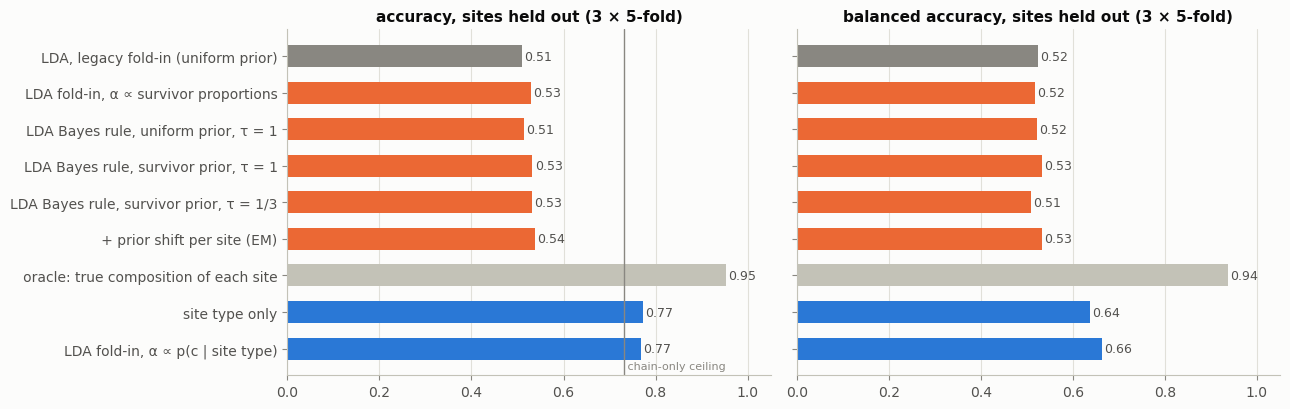

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
t = R.table("CV, sites", selection_variants).droplevel("protocol")
colors = [pl.INK["muted"]] + [pl.COLORS["EFG"]] * 5 + [pl.INK["axis"]] + [pl.COLORS["CW"]] * 2
for ax, metric, title in zip(axes, ["accuracy", "balanced_acc"], ["accuracy", "balanced accuracy"]):
    pl.hbars(ax, selection_variants, t[metric].values, colors,
             ref=ceiling["BoK (4 classes)"] if metric == "accuracy" else None,
             ref_label="chain-only ceiling" if metric == "accuracy" else None)
    ax.set_xlim(0, 1.05); ax.set_title(f"{title}, sites held out (3 × 5-fold)")
axes[1].set_yticklabels([])
fig.tight_layout(); plt.show()

**Reading the table.**
- Restoring the survivor prior helps a little: the asymmetric-Dirichlet fold-in raises the accuracy of the legacy classifier (0.51 → 0.53 with sites held out) and lowers its log-loss at unchanged calibration, while balanced accuracy drops slightly — the trade the Lemma predicts. With $\tau=1/3$ the survivor prior does the same; with $\tau=1$ the likelihood is so over-confident that the prior hardly changes any decision.
- $\tau=1$ Bayes rules are grossly over-confident (log-loss ≈ 2.8, ECE ≈ 0.37); the composite-likelihood correction $\tau=1/3$ halves the log-loss at equal accuracy.
- Adapting each site's composition from its unlabelled chains adds little: the chain-level evidence is too weak to identify a site's composition. Yet the **oracle** shows that the composition of an assemblage is worth almost everything (accuracy ≈ 0.95), because sites are nearly single-culture. **The information is in the selection, not in the chains.**
- Modelling the selection through the observed find context lifts LDA from 0.51 to about 0.77 with sites held out. Next to the context alone, at equal accuracy, the chain still improves balanced accuracy (0.64 → 0.66), macro-F1 (0.60 → 0.66) and log-loss.

### 2.5 The assumptions behind the context model
$X\perp K\mid C,S=1$ says that, within a culture, the chain does not depend on the kind of site. It can be probed where a culture occurs in more than one site type: χ² tests of independence between the use of key techniques and the site type, within each culture.

In [8]:
techniques_ = {"burnishing": "Burnishing", "shining": "Shining", "scraping": "Scraping",
               "separate element": "Application separate element", "simple impression": "Simple impression",
               "simple incision": "Simple incision"}
rows = []
for c in BOKS:
    sub = df[df["bok"] == c]
    for name, tech in techniques_.items():
        table = pd.crosstab(sub["site_type"], sub["steps"].map(lambda s, tech=tech: tech in s))
        if table.shape[0] > 1 and table.shape[1] > 1:
            rows.append({"technique": name, "culture": c, "p": chi2_contingency(table)[1]})
ci = pd.DataFrame(rows).pivot(index="technique", columns="culture", values="p")
print(f"{int((ci < 0.05).sum().sum())} of {int(ci.notna().sum().sum())} tests with p < 0.05 "
      f"(≈ {0.05 * ci.notna().sum().sum():.1f} expected by chance)")
ci

2 of 23 tests with p < 0.05 (≈ 1.2 expected by chance)


culture,CW,EFG,LFG,MI
technique,,,,
burnishing,0.665,0.129,0.082,0.317
scraping,0.133,0.054,0.082,1.000
separate element,0.084,0.685,0.124,1.000
shining,0.177,0.677,NaN,1.000
simple impression,0.754,0.625,0.310,0.820
simple incision,0.799,0.025,0.035,1.000


**How to read it.**
- *Entries* are p-values of χ² tests of independence between using a technique and the site type, within one culture. A small value means the technique's use depends on the site type.
- *NaN:* the test is impossible, because the technique is never (or always) used in that culture.
- *1.000 for middle FBW:* 94 of its 95 vessels come from megaliths, so there is nothing to compare. This is no evidence of independence.
- Only the tests for CW (three known site types and an unknown one, 89 vessels) and for early and late FBW (three site types each, one of them with a single vessel) have any power.

Two of 23 tests fall below 0.05 (simple incision within early and late FBW), about what chance produces (≈ 1.2), and neither survives a Bonferroni correction (threshold 0.05/23 ≈ 0.002). The data are consistent with $X\perp K\mid C$ — but this is weak evidence: the tests have little power (MI is almost entirely from megaliths, LFG and EFG from few sites), and χ² with small expected counts is approximate. Two further caveats. (i) If the BoK labels were assigned partly *from* the find context (e.g. a vessel attributed to a phase because of where it was found), predicting them from the context is circular; the context model is then only as meaningful as the independence of the labelling from the context. (ii) The context carries no information about *how* a vessel was made: it helps attribution, not the study of technical traditions.

### 2.6 What survival does change: the population
If survival were selective, what the potters did differs from what we see. Under the hypothetical selection of 2.2 (burnished vessels survive with odds $r$), the inverse-probability estimates of the population move with $r$: at $r=5$ the CW share rises from 0.32 to 0.51, and the share of burnished vessels falls in every culture (CW 0.43 → 0.13, MI 0.85 → 0.54). The attribution of survivors does not move (Prop. 1, verified above). These statements need an external estimate of $r$; the survivors alone cannot provide it (Prop. 3b).

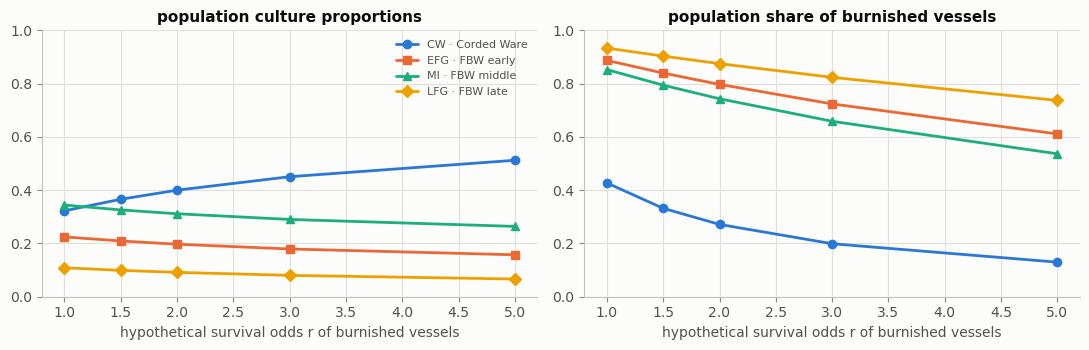

ρ_c                      P(burnished | c)                     
        CW    EFG     MI    LFG               CW    EFG     MI    LFG
r                                                                    
1.0  0.322  0.225  0.344  0.109            0.427  0.887  0.853  0.933
1.5  0.366  0.209  0.326  0.099            0.332  0.840  0.794  0.903
2.0  0.400  0.197  0.311  0.091            0.271  0.797  0.743  0.875
3.0  0.450  0.179  0.290  0.080            0.199  0.724  0.659  0.824
5.0  0.512  0.157  0.264  0.066            0.130  0.611  0.536  0.737

In [9]:
rs = [1, 1.5, 2, 3, 5]
rows = []
for r in rs:
    s_x, p_x_c, rho_r = ipw_population(r)
    burnt = burnished_chain.reindex(p_x_c.index).to_numpy()
    rows.append({"r": r, **{("ρ_c", c): rho_r[c] for c in BOKS},
                 **{("P(burnished | c)", c): p_x_c[c][burnt].sum() for c in BOKS}})
pop = pd.DataFrame(rows).set_index("r"); pop.columns = pd.MultiIndex.from_tuples(pop.columns)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, block, title in zip(axes, ["ρ_c", "P(burnished | c)"], ["population culture proportions", "population share of burnished vessels"]):
    for c in BOKS:
        ax.plot(rs, pop[(block, c)], color=pl.COLORS[c], marker=pl.MARKERS[c], ms=6, label=pl.label(c))
    ax.set_xlabel("hypothetical survival odds r of burnished vessels"); ax.set_title(title); ax.set_ylim(0, 1)
axes[0].legend(fontsize=8); fig.tight_layout(); plt.show()
pop.round(3)

**How to read it.**
- *Rows:* hypothetical survival odds $r$ of burnished vessels; $r=1$ is the sample itself.
- *Columns:* for each $r$, the population estimated by inverse-probability weighting: the culture proportions $\rho_c$ (left) and the share of burnished vessels within each culture (right).
- *What it shows:* conclusions about the *population* depend strongly on an assumption the data cannot check (Prop. 3). At $r=5$, CW becomes the majority (0.51), and burnishing becomes rare in CW (0.13) and falls from 0.85 to 0.54 in middle FBW. The attribution of survivors does not change at all (Prop. 1).

### 2.7 Answer
- A survival term $P(S=1\mid x)$ that depends on the chain **cannot** improve attribution of vessels selected like the training vessels: it cancels (Prop. 1), and for token-wise survival the fitted topics simply absorb it (Theorem, verified to machine precision).
- What *can* improve LDA is to stop discarding the selection that shaped the data. That means using the survivor proportions (a small gain), adapting to each assemblage's composition (small here, because the chains are weak evidence), and above all modelling the selection through the find context (a large gain, under a stated independence assumption and with a circularity caveat).
- Survival matters for the **population**: the practice as it was and the culture proportions. Without external information it is not identifiable (Prop. 3b).

## 3 · Maximum Caliber (theory sketch)

*Moved from Section 11 of the main notebook.*

**Principle** (Jaynes 1980; Pressé et al. 2013). Among all distributions over whole chains $\Gamma$, choose the one of maximum path entropy $S=-\sum_\Gamma P(\Gamma)\ln P(\Gamma)$ that reproduces chosen averages $\langle A_k(\Gamma)\rangle=a_k$:
$$P(\Gamma)=\frac{1}{Z(\lambda)}\exp\Big(\sum_k\lambda_k A_k(\Gamma)\Big),\qquad \min_\lambda\;\ln Z(\lambda)-\lambda\cdot a .$$
The chain space here is finite, so $Z$ is an explicit sum (`maxcal.py`).

**What the constraints say.** If the $A_k$ count each *transition* $i\to j$ (Kroon's edge weights), the MaxCal distribution is the **first-order Markov chain** with $p_{ij}=n_{ij}/n_i$; with triplet counts it is the second-order chain. The Markov models of Section 10 of the main notebook *are* MaxCal models — equivalently, by its Proposition 4, walks on the n-gram networks $G_n$ — and its Section 10.3 tests which constraints are needed. Numerical check (paths enumerated up to a probability cut-off; the gap closes as the cut-off → 0):

In [10]:
mle = markov.MarkovChain(1, beta=0.0, alpha=0.0).fit(df["steps"])       # unsmoothed, no grammar
for cutoff in [1e-6, 1e-7]:
    paths, mass = markov.enumerate_paths(mle, max_len=30, min_prob=cutoff)
    p_markov = np.array([p for _, p in paths]); p_markov /= p_markov.sum()
    F, feat = maxcal.feature_matrix([s for s, _ in paths], maxcal.transition_features)
    col = {k: j for j, k in enumerate(feat)}
    target = np.zeros(len(feat))
    for s in df["steps"]:
        for k, n in maxcal.transition_features(s).items():
            target[col[k]] += n / len(df)
    lam, p_mc, res = maxcal.fit_maxcal(F, target)
    print(f"cut-off {cutoff:g}: {len(paths)} chains ({mass:.4f} of the mass); "
          f"total-variation distance MaxCal vs Markov = {0.5 * np.abs(p_mc - p_markov).sum():.4f}")

cut-off 1e-06: 7280 chains (0.9936 of the mass); total-variation distance MaxCal vs Markov = 0.0117


cut-off 1e-07: 21561 chains (0.9982 of the mass); total-variation distance MaxCal vs Markov = 0.0038


**How to read it.** The MaxCal distribution constrained by the observed transition counts is compared with the first-order Markov chain over the enumerated chains. Their total-variation distance (half the summed absolute difference; 0 = identical, 1 = disjoint) is:
- 0.012 when chains below probability $10^{-6}$ are dropped (0.6 % of the mass missing);
- 0.004 at $10^{-7}$ (0.2 % missing).

The gap shrinks with the truncation, as it must if the two are equal on the full chain space.

**Beyond n-grams: BoK-specific "forces".** Take the pooled first-order process $Q(\Gamma)$ as reference and ask, for each BoK, for the least-biased change of $Q$ that reproduces a few BoK-level averages — decoration steps, burnishing, shining, scraping, separately applied elements (handles, knobs), smudging, chain length:
$$P_b(\Gamma)\propto Q(\Gamma)\,\exp\Big(\sum_k\mu_{b,k}A_k(\Gamma)\Big).$$
Each $\mu_{b,k}$ is the log-odds "push" of BoK $b$ on feature $k$ relative to shared practice (a Gaussian prior keeps absent features finite).

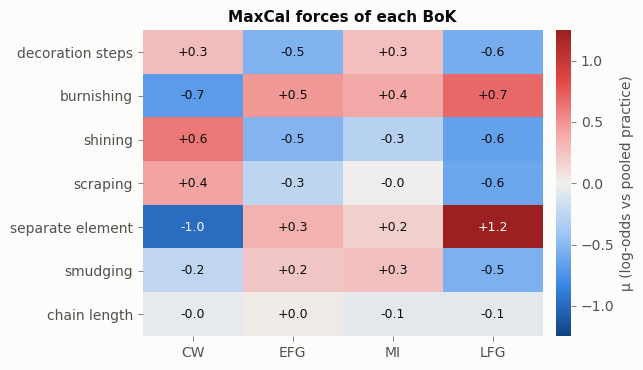

In [11]:
paths, _ = markov.enumerate_paths(mle, max_len=30, min_prob=1e-7)
space = [s for s, _ in paths]
log_q = np.log([p for _, p in paths])
DECOR = {"Simple impression", "Tilted impression", "Simple incision", "Excisions", "Incrustation", "Application"}
def features(s):
    return {"decoration steps": sum(x in DECOR for x in s), "burnishing": "Burnishing" in s,
            "shining": "Shining" in s, "scraping": "Scraping" in s,
            "separate element": "Application separate element" in s, "smudging": "Smudging" in s,
            "chain length": len(s)}
fnames = list(features(space[0]))
F = np.array([[features(s)[k] for k in fnames] for s in space], float)
forces = {}
for b in BOKS:
    target = np.array([[features(s)[k] for k in fnames] for s in groups[b]], float).mean(0)
    mu, _, res = maxcal.fit_maxcal(F, target, log_prior=log_q, l2=0.1)
    forces[b] = mu
forces = pd.DataFrame(forces, index=fnames)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
lim = np.abs(forces.values).max()
pl.heatmap(ax, forces.values, fnames, BOKS, cmap=pl.DIV, center=0, vmin=-lim, vmax=lim, fmt="{:+.1f}",
           cbar_label="μ (log-odds vs pooled practice)")
ax.set_title("MaxCal forces of each BoK"); fig.tight_layout(); pl.save(fig, "maxcal_forces"); plt.show()

**How to read it.**
- *Entries:* $\mu_{b,k}$, the log-odds push of BoK $b$ on feature $k$ relative to the pooled practice. $\mu=+0.7$ multiplies the weight of every chain with that feature by $e^{0.7}\approx2$; $\mu=-1.0$ divides it by $e\approx2.7$. For counted features (decoration steps, chain length) the push applies per step.
- *Numbers:* the strongest forces concern:
  - separately applied elements (CW −1.0, late FBW +1.2);
  - burnishing (CW −0.7, FBW +0.4 to +0.7);
  - shining (CW +0.6, FBW −0.3 to −0.6).

  Chain length is ≈ 0 everywhere: no BoK makes longer chains than the others.
- *Caveat:* no uncertainty is attached, and late FBW's forces rest on 30 vessels. The Gaussian prior (l2 = 0.1) shrinks all forces toward 0.

CW potters avoid separately applied elements and burnishing and favour shining and scraping; the FBW phases favour burnishing and applied elements, most strongly in the late phase, which also drops shining, scraping and smudging.

**Next steps.** Compare nested constraint sets by held-out likelihood (as in Section 10.3 of the main notebook); fit $\mu$ per FBW phase and read the drift EFG → MI → LFG as a trajectory (radiocarbon dates in Kroon's deposit could give a time axis); test whether CW is better described with an interaction term $e^{\epsilon\,\mu_{FBW}\cdot A}$ (borrowing from FBW potters, Kroon's "serial learning"); restrict the path space to Kroon's grammar.

Part 6 joins this picture to survival and to attribution.

## 4 · Lost steps: the deletion channel

Part 2 is about pots that are lost. Now the pot survives, but some of its steps do not. A burnished surface weathers, an impression fills with sediment, a scraped surface goes unrecognised. The recorded chain $Y$ is then a *subsequence* of the true chain $X$, and nothing in the record says where anything is missing. This is the hidden Markov model of the question: the chain as made is hidden, and the chain that survived is what we observe. Let us work it out exactly.

### 4.1 Four kinds of missing data
Rubin (1976) sorts missing data by what the chance of being missing depends on:
- **MCAR** (missing completely at random): it depends on nothing;
- **MAR** (missing at random): it depends only on what is observed;
- **MNAR** (missing not at random): it depends on the missing values themselves.

Under MCAR or MAR, if the missingness has its own parameters, the likelihood that integrates out the missing values gives valid inference and the mechanism can be ignored (Little & Rubin 2019). Under MNAR the mechanism must be modelled.

| what is missing | in statistics | mechanism here | likelihood to use | identifiable from the records? |
|---|---|---|---|---|
| whole pots (not deposited, destroyed, not excavated) | selection, truncation | $s(x,c,\text{site})$ | weighted distribution (2.1) | attribution yes; practice and proportions no (Prop. 3) |
| the end of a chain (a broken pot) | right censoring | where the pot breaks, unrelated to the later steps (MAR) | marginal of the prefix, $p(x_{1:t})$ (main notebook, 10.5) | yes |
| steps erased inside a chain | deletion channel, MNAR | step $v$ kept with probability $\sigma_v$, by site | the record is Markov with kernel $K$ (Prop. 5) | practice only given $\sigma$; $\sigma$ only relative to a reference (Cor. 5) |
| old vs recent excavations, different recorders | MAR given the excavation | $\sigma$ depends on site, era, recorder | condition on these covariates | yes, if they are recorded |

A step erased from inside a chain is MNAR in the strongest sense: a step can be lost only if it was there, and the record does not even mark the place. Every model in the main notebook treats the record as the complete chain, which means ignoring this mechanism.

### 4.2 The surviving chain is again a Markov chain
Add START and END to the techniques. The original chain moves with the kernel $P$: its rows are START and the techniques, its columns are the techniques and END, and $P\mathbf 1=\mathbf 1$. From every state it reaches END with probability 1. Each visit to technique $v$ survives independently with probability $\sigma_v$, and $\sigma_{\rm START}=\sigma_{\rm END}=1$. Write $S=\mathrm{diag}(\sigma)$ and $D=I-S$.

**Proposition 5 (deletion channel).** The recorded chain $Y$ is a first-order Markov chain with kernel
$$K=(I-PD)^{-1}PS .$$
Here $K_{uw}$ is the probability that, after a surviving visit to $u$, the next surviving visit is to $w$ (or END). Its rows sum to 1, and
$$P(Y=y)=\prod_{i=0}^{m}K_{y_iy_{i+1}},\qquad y_0={\rm START},\;y_{m+1}={\rm END}.$$

*Proof.*
1. *Convergence.* END is reached with probability 1 from every state, so the technique block of $P$ has spectral radius $<1$. Since $0\le PD\le P$ entrywise, $\rho(PD)<1$ as well (Perron–Frobenius), and $(I-PD)^{-1}=\sum_{k\ge0}(PD)^k$ converges.
2. *Markov property.* Suppose the last surviving visit was to $u$. The future of $X$ is then independent of its past (Markov property), and so are the future survival coins. So the next recorded symbol depends on $u$ only, and $Y$ is Markov.
3. *The kernel.* The next survivor is $w$ when $k\ge0$ erased visits $u\to v_1\to\dots\to v_k$ are followed by a surviving visit to $w$. Summing over $k$ gives $\sum_k[(PD)^kPS]_{uw}=K_{uw}$.
4. *Rows.* $PS\mathbf1=P\mathbf1-PD\mathbf1=(I-PD)\mathbf1$, so $K\mathbf 1=\mathbf 1$. $\square$

**Corollary 5 (what the record can tell).**
- (a) Given $\sigma$, the original chain is recovered exactly: $K=PS+PDK$, so $P=K(S+DK)^{-1}$.
- (b) Without $\sigma$ it is not. Taking $\sigma\equiv1$ and $P=K$ fits every record perfectly, so "nothing was lost" can never be refuted from one population's records. This is Proposition 3 at the level of steps.
- (c) Suppose several sites share one practice $P$ and one of them is complete ($\sigma=1$). Its records give $P=K$ directly, and the other sites' $\sigma$ can then be estimated from how their kernels differ from $P$.

**Which steps can be lost?** This is an assumption, not a measurement. Two kinds of steps sit on the surface and can weather away or go unnoticed:
- the surface treatments: burnishing, shining, smudging, scraping;
- the decorations: impressions, incisions, excisions, incrustation, applied decoration.

Forming, smoothing, drying and firing leave traces in the body, or are implied by the pot's existence. The 10 *fragile* steps get $\sigma<1$; all others get $\sigma=1$.

In [12]:
# Augmented state space: techniques 0 … V−1, START = V, END = V + 1
V, idx = len(vocab), {v: i for i, v in enumerate(vocab)}
iS, iE = V, V + 1
FRAGILE = {"Burnishing", "Shining", "Smudging", "Scraping",                           # surface treatments
           "Simple impression", "Tilted impression", "Simple incision", "Excisions",  # decoration
           "Incrustation", "Application"}
frag = np.array([v in FRAGILE for v in vocab] + [False, False])
SUP = np.zeros((V + 2, V + 2), bool)          # where the original chain may move:
for a in vocab:                               # Kroon's links (+ the one observed extra link),
    SUP[idx[a], [idx[b] for b in grammar.successors[a] if b in idx]] = True
SUP[iS, idx["Wet clay"]] = True               # every chain starts with wet clay,
SUP[:V, iE] = True                            # and may end after any step

def survival(s):
    """σ: fragile steps survive with probability s; all other steps, START and END with 1."""
    return np.where(frag, s, 1.0)

def channel(P, sigma):
    """Proposition 5: N = (I − PD)⁻¹, the kernel of the recorded chain K = N P S, and M = S + D K."""
    S = np.diag(sigma); D = np.eye(V + 2) - S
    N = np.linalg.inv(np.eye(V + 2) - P @ D)
    K = N @ P @ S
    return N, K, S + D @ K

def augment(steps):
    return [iS] + [idx[v] for v in steps] + [iE]

def segment_counts(chains):
    """R[u, w]: how often a recorded chain goes from u to w (START and END included)."""
    R_ = np.zeros((V + 2, V + 2))
    for s in chains:
        y = augment(s)
        np.add.at(R_, (y[:-1], y[1:]), 1)
    return R_

def markov_kernel(chains, beta=0.1):
    """First-order kernel on SUP, taking the records as complete (σ ≡ 1); Dirichlet(β) smoothing."""
    C = np.where(SUP, segment_counts(chains) + beta, 0.0)
    return C / C.sum(1, keepdims=True).clip(1e-300)

def record_loglik(K, chains):
    """log P(Y = y) = Σ_i log K[y_i, y_i+1] for every recorded chain (Proposition 5)."""
    with np.errstate(divide="ignore"):
        return np.array([np.log(K[y[:-1], y[1:]]).sum() for y in map(augment, chains)])

def simulate(P, s, n, rng, max_len=40):
    """n recorded chains: walk the original chain P, then erase each fragile visit with probability 1 − s."""
    out = []
    while len(out) < n:
        a, x = iS, []
        while len(x) < max_len:
            a = rng.choice(V + 2, p=P[a])
            if a == iE:
                break
            x.append(a)
        out.append([vocab[v] for v in x if not frag[v] or rng.random() < s])
    return out

**Check.** Take the pooled first-order practice $P$ (Kroon's links as the support) and keep fragile steps with $\sigma=0.6$. We compare:
- the closed form with the Neumann series;
- $P$ with the inversion of Corollary 5(a);
- $K$ with a simulation of 50 000 eroded chains.

In [13]:
P_all = markov_kernel(df["steps"])               # pooled practice, records taken as complete
sig = survival(0.6)
N, K, M = channel(P_all, sig)
S_, D_ = np.diag(sig), np.diag(1 - sig)
neumann, term = np.zeros_like(K), P_all @ S_
for _ in range(300):
    neumann += term; term = P_all @ D_ @ term
rng = np.random.default_rng(SEED)
R_sim = segment_counts(simulate(P_all, 0.6, 50_000, rng))
n_row = R_sim.sum(1, keepdims=True).clip(1)
testable = (R_sim.sum(1, keepdims=True) > 0) & (K > 0) & (K < 1)
with np.errstate(divide="ignore", invalid="ignore"):
    z = ((R_sim / n_row - K) / np.sqrt(K * (1 - K) / n_row))[testable]   # binomial z-score of every transition
pd.Series({
    "spectral radius of PD (must be < 1)": max(abs(np.linalg.eigvals(P_all @ D_))),
    "max |row sum of K − 1|": np.abs(K[:iE].sum(1) - 1).max(),
    "max |K − Σ_k (PD)^k PS|  (300 terms)": np.abs(K - neumann).max(),
    "max |P − K (S + DK)⁻¹|  (Corollary 5a)": np.abs(P_all - K @ np.linalg.inv(S_ + D_ @ K)).max(),
    f"simulation, 50 000 chains: largest |z| over {z.size} transitions": np.abs(z).max(),
    "  … Bonferroni p-value of that largest |z|": min(1.0, z.size * 2 * norm.sf(np.abs(z).max())),
}).to_frame("value")

,value
spectral radius of PD (must be < 1),8.757e-02
max |row sum of K − 1|,4.441e-16
max |K − Σ_k (PD)^k PS| (300 terms),3.331e-16
max |P − K (S + DK)⁻¹| (Corollary 5a),2.220e-16
"simulation, 50 000 chains: largest |z| over 219 transitions",3.448e+00
… Bonferroni p-value of that largest |z|,1.238e-01


Every identity holds to machine precision. The simulated record transitions agree with $K$ within sampling noise: the largest of 219 binomial z-scores is 3.4, with Bonferroni p = 0.12. The spectral radius of $PD$ is 0.09, so erasures rarely come in runs: a gap usually hides at most one step.

### 4.3 Does modelling erosion help attribution?
We erode held-out pots on purpose (sites held out): each fragile step is kept with probability $q$. Each community's practice $P_c$ is fitted to the training records. Three attributions are compared:
- the records taken as complete ($\sigma=1$, the main notebook's assumption);
- the channel with a rough guess, $\sigma=0.5$;
- the channel with the true $q$.

In [14]:
def channel_proba(kernels, prior, chains, s):
    """p(c | y) ∝ π_c P(y | c), with the recorded kernel of every culture under survival s of the fragile steps."""
    L = np.column_stack([record_loglik(channel(kernels[c], survival(s))[1], chains) for c in BOKS])
    L = np.where(np.isfinite(L), L, -1e9)        # a record impossible under every culture falls back to the prior
    return softmax_rows(L + np.log(prior))

def kernels_and_prior(train):
    kernels = {c: markov_kernel(train.loc[train["bok"] == c, "steps"]) for c in BOKS}
    prior = (train["bok"].astype(str).value_counts().reindex(BOKS).to_numpy() + 1) / (len(train) + len(BOKS))
    return kernels, prior

erosion = [1.0, 0.75, 0.5, 0.25]                 # true survival q of the fragile steps on the held-out vessels
assumed = {"records taken as complete (σ = 1)": lambda q: 1.0,
           "channel, σ guessed = 0.5": lambda q: 0.5,
           "channel, true σ = q": lambda q: q}
rows, rng = [], np.random.default_rng(SEED)
for seed in range(3):
    for tr, te in ev.splits(df, "site", 5, seed):
        test = df.iloc[te]
        kernels, prior = kernels_and_prior(df.iloc[tr])
        for q in erosion:
            eroded = [[v for v in s if v not in FRAGILE or rng.random() < q] for s in test["steps"]]
            for name, s_of in assumed.items():
                rows.append((q, name, test["bok"].astype(str).to_numpy(), channel_proba(kernels, prior, eroded, s_of(q))))
erosion_table = pd.DataFrame([{"survival q": q, "model": name, **ev.scores(np.concatenate([r[2] for r in rows if r[:2] == (q, name)]),
                                                                       np.vstack([r[3] for r in rows if r[:2] == (q, name)]))}
                              for q in erosion for name in assumed])
erosion_table.pivot(index="survival q", columns="model", values=["accuracy", "log_loss"]).sort_index(ascending=False)

accuracy                           \
model      channel, true σ = q channel, σ guessed = 0.5   
survival q                                                
1.00                     0.539                    0.541   
0.75                     0.518                    0.512   
0.50                     0.484                    0.484   
0.25                     0.466                    0.458   

                                                        log_loss  \
model      records taken as complete (σ = 1) channel, true σ = q   
survival q                                                         
1.00                                   0.539               1.164   
0.75                                   0.518               1.167   
0.50                                   0.452               1.222   
0.25                                   0.415               1.226   

                                                                       
model      channel, σ guessed = 0.5 records taken as complete (σ = 1)  
survival q                                                             
1.00                          1.145                             1.164  
0.75                          1.163                             1.200  
0.50                          1.222                             1.295  
0.25                          1.234                             1.300

**How to read it.**
- *Rows:* the true survival $q$ of fragile steps on the artificially eroded held-out vessels ($q=1$: no erosion).
- *Columns:* accuracy and log-loss of the three attributions (sites held out, 3 × 5-fold, $n$ = 828 per cell).
- *Evidence:*
  - the channel's accuracy gains (+0.03 at $q=0.5$, +0.05 at $q=0.25$) are about one standard error of a paired difference (± 0.04–0.05, end of Part 7), so they are suggestive, not proven;
  - the log-loss gains (≈ 0.07 at $q\le0.5$) go the same way at every $q$, and are the more robust result.
- *Caveat:* the erosion is simulated under the model's own assumption that the 10 fragile steps are lost independently. Real erosion may be correlated: a weathered surface loses all its treatments at once.

- **Intact pots ($q=1$).** Nothing changes. The guess $\sigma=0.5$ even lowers the log-loss a little, as if some real records already miss steps; this is a hint, not a proof.
- **Eroded pots.** Taking the record at face value loses accuracy fast: 0.54 → 0.42 at $q=0.25$. The channel loses less (0.47) and keeps the log-loss lower, and a rough guess of $\sigma$ does nearly as well as the truth.

The gain is real but modest. Erosion removes information and no model can put it back; the channel only stops the model from being misled by what is absent.

### 4.4 Original vs surviving practice across sites (EM)
This is the question's hidden Markov model, with sites added: one original practice $P_c$ per community, and a survival $\sigma_s$ of the fragile steps at each site. The hidden quantities are the erased visits. Baum–Welch (EM) needs their expected numbers given the records, and Proposition 5 gives them in closed form.

For a gap $u\to w$ between consecutive recorded symbols:
- *Expected transitions.* The number of original transitions $a\to b$ inside the gap is, in expectation, $N_{ua}P_{ab}M_{bw}/K_{uw}$, with $N=(I-PD)^{-1}$ and $M=S+DK$. In words: the path reaches $a$ through erased visits ($N$), moves to $b$ ($P$), and from $b$ the next survivor is $w$ ($M$).
- *Expected erased visits.* The number of erased visits to $b$ is, in expectation, $D_b\,(NP)_{ub}\,K_{bw}/K_{uw}$.

Summing over all gaps, with $Q_{uw}=R_{uw}/K_{uw}$ and $R$ the gap counts:
$$\mathbb E[n_{ab}]=P_{ab}\,(N^{\top}QM^{\top})_{ab},\qquad \mathbb E[\text{erased visits to }b]=D_b\textstyle\sum_aP_{ab}\,(N^{\top}QK^{\top})_{ab}.$$
- *M-step.* $P_{ab}\propto\mathbb E[n_{ab}]+\beta$ on Kroon's links, and $\sigma_s$ = recorded fragile visits / (recorded + expected erased) at site $s$.
- *Monotonicity.* EM never decreases the (penalised) likelihood (Baum et al. 1970; Dempster, Laird & Rubin 1977).
- *Reference site.* By Corollary 5 one site must be fixed. We set $\sigma=1$ at the site with the most fragile steps per vessel, so every $\hat\sigma_s$ is survival *relative to the best-preserved site*.

We check on synthetic data first: two sites with the same practice, $\sigma$ = 1 and 0.4. EM must recover $\sigma$ and must agree with the maximum of the profile likelihood.

,mean_sigma_B,sd_sigma_B,monotone,iterations
vessels per site,,,,
30,0.425,0.052,True,31.0
100,0.407,0.031,True,27.0
1000,0.393,0.012,True,22.5


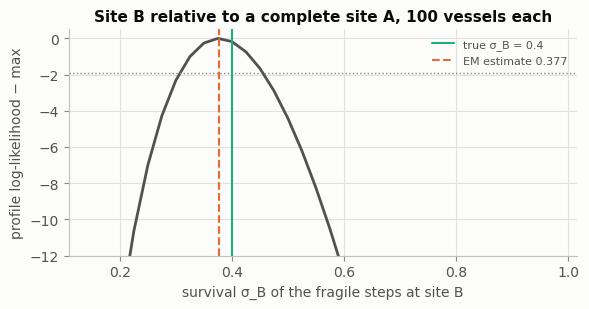

EM 0.377; profile maximum 0.378 (grid step 0.0025); 95% likelihood interval ≈ [0.32, 0.45]


In [15]:
def em(chains_by_group, sigma0, free=(), beta=0.1, max_iter=2000, tol=1e-10):
    """Baum–Welch for the deletion channel. One original kernel P shared by all groups (sites); survival σ_g of the
    fragile steps per group; groups in `free` are estimated, the others stay at sigma0. Dirichlet(β) prior on P.
    Returns P, σ, log-likelihood, and the trace of the penalised log-likelihood (EM never decreases it)."""
    R_ = {g: segment_counts(c) for g, c in chains_by_group.items()}
    sig, P, trace = dict(sigma0), SUP / SUP.sum(1, keepdims=True).clip(1), []
    for _ in range(max_iter):
        C, ll, kept, lost = beta * SUP, 0.0, {}, {}
        for g, Rg in R_.items():
            sv = survival(sig[g]); N, K, M = channel(P, sv)
            m = Rg > 0
            if np.any(K[m] <= 0):                                         # a record this σ cannot produce
                return P, sig, -np.inf, np.array(trace + [-np.inf])
            ll += (Rg[m] * np.log(K[m])).sum()
            Q = np.where(m, Rg, 0.0) / np.where(m, K, 1.0)
            C = C + P * (N.T @ Q @ M.T)                                   # E-step: expected transitions a → b
            lost[g] = ((1 - sv) * (P * (N.T @ Q @ K.T)).sum(0))[frag].sum()   # expected erased fragile visits
            kept[g] = Rg[:, frag].sum()                                   # recorded fragile visits
        trace.append(ll + beta * np.log(P[SUP]).sum())
        if len(trace) > 1 and trace[-1] - trace[-2] < tol * abs(trace[-1]):
            break
        P = C / C.sum(1, keepdims=True).clip(1e-300)                     # M-step
        for g in free:
            sig[g] = kept[g] / (kept[g] + lost[g])
    return P, sig, ll, np.array(trace)

# synthetic check: two sites with the same practice (MI), survival 1 and 0.4
P_true = markov_kernel(groups["MI"], beta=0.5)
rng = np.random.default_rng(SEED)
rows = []
for n in (30, 100, 1000):
    for rep in range(10):
        sites = {"A": simulate(P_true, 1.0, n, rng), "B": simulate(P_true, 0.4, n, rng)}
        P_hat, s_hat, _, trace = em(sites, {"A": 1.0, "B": 0.8}, free=["B"])
        rows.append({"vessels per site": n, "σ̂_B": s_hat["B"], "EM never decreases": bool(np.all(np.diff(trace) >= -1e-8)),
                     "iterations": len(trace)})
display(pd.DataFrame(rows).groupby("vessels per site").agg(
    mean_sigma_B=("σ̂_B", "mean"), sd_sigma_B=("σ̂_B", "std"), monotone=("EM never decreases", "all"), iterations=("iterations", "median")))

# the EM estimate must sit at the maximum of the profile likelihood ℓ(σ_B) = max_P ℓ(P, σ_B)
sites = {"A": simulate(P_true, 1.0, 100, rng), "B": simulate(P_true, 0.4, 100, rng)}
s_em = em(sites, {"A": 1.0, "B": 0.8}, free=["B"])[1]["B"]
grid = np.linspace(0.15, 1.0, 35)
profile = np.array([em(sites, {"A": 1.0, "B": s})[3][-1] for s in grid])
fine = np.linspace(grid[profile.argmax()] - 0.03, grid[profile.argmax()] + 0.03, 25)
s_prof = fine[np.argmax([em(sites, {"A": 1.0, "B": s})[3][-1] for s in fine])]
inside = grid[2 * (profile.max() - profile) <= 3.84]
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(grid, profile - profile.max(), color=pl.INK["secondary"])
ax.axhline(-3.84 / 2, color=pl.INK["muted"], lw=1, ls=":")
ax.axvline(0.4, color=pl.COLORS["MI"], lw=1.5, label="true σ_B = 0.4")
ax.axvline(s_em, color=pl.COLORS["EFG"], lw=1.5, ls="--", label=f"EM estimate {s_em:.3f}")
ax.set_ylim(-12, 0.5); ax.set_xlabel("survival σ_B of the fragile steps at site B")
ax.set_ylabel("profile log-likelihood − max"); ax.legend(fontsize=8)
ax.set_title("Site B relative to a complete site A, 100 vessels each")
fig.tight_layout(); plt.show()
print(f"EM {s_em:.3f}; profile maximum {s_prof:.3f} (grid step 0.0025); "
      f"95% likelihood interval ≈ [{inside.min():.2f}, {inside.max():.2f}]")

EM recovers $\sigma_B$ without bias as the sample grows (0.43 ± 0.05 with 30 pots per site, 0.39 ± 0.01 with 1000). It never decreases its objective, and it lands on the maximum of the profile likelihood (0.377 vs 0.378; the dotted line marks the 95 % likelihood-ratio threshold). With 100 pots per site, the 95 % interval is about ± 0.07.

**Real sites.** For each community we use the sites with at least 5 vessels. Corded Ware sites are mostly single barrows, so for CW we group by site *type* instead. The reference is the group with the most fragile steps per vessel.

We test "nothing lost anywhere" ($\sigma\equiv1$) against "survival differs between sites" with a parametric bootstrap of the likelihood ratio. The null value $\sigma=1$ lies on the boundary of the parameter space, so χ² tables do not apply (Self & Liang 1987).

In [16]:
def fragile_per_vessel(chains):
    return np.mean([sum(v in FRAGILE for v in s) for s in chains])

def site_survival(sub, by, n_min=5, B=200, rng=None):
    """EM with one practice for the culture and survival per group (site, or site type); reference = the group
    with the most fragile steps per vessel. Likelihood-ratio test against σ ≡ 1 by parametric bootstrap,
    and 90% bootstrap intervals for σ̂."""
    sizes = sub[by].value_counts()
    sub = sub[sub[by].isin(sizes[sizes >= n_min].index)]
    chains = {g: list(x["steps"]) for g, x in sub.groupby(by)}
    rate = {g: fragile_per_vessel(c) for g, c in chains.items()}
    ref = max(rate, key=rate.get); free = [g for g in chains if g != ref]
    start = {g: 1.0 if g == ref else 0.8 for g in chains}
    P1, s1, ll1, _ = em(chains, start, free)
    P0, _, ll0, _ = em(chains, {g: 1.0 for g in chains})
    null = []
    for _ in range(B):                                   # H0: one practice, nothing erased anywhere
        sim = {g: simulate(P0, 1.0, len(c), rng) for g, c in chains.items()}
        null.append(2 * (em(sim, start, free)[2] - em(sim, {g: 1.0 for g in sim})[2]))
    boot = []
    for _ in range(B // 2):                              # intervals: resimulate from the fitted model
        sim = {g: simulate(P1, s1[g], len(c), rng) for g, c in chains.items()}
        boot.append(em(sim, start, free)[1])
    lo = {g: np.quantile([b[g] for b in boot], 0.05) for g in chains}
    hi = {g: np.quantile([b[g] for b in boot], 0.95) for g in chains}
    lr = 2 * (ll1 - ll0)
    table = pd.DataFrame({"vessels": {g: len(c) for g, c in chains.items()}, "fragile steps per vessel": rate,
                          "σ̂": s1, "5%": lo, "95%": hi,
                          "site type": sub.groupby(by)["site_type"].agg(lambda x: ", ".join(sorted(set(x))))})
    return table.sort_values("σ̂"), lr, (1 + np.sum(np.array(null) >= lr)) / (1 + B), len(free)

rng = np.random.default_rng(SEED)
survival_tables, tests = {}, []
for c, by in [("EFG", "site_id"), ("MI", "site_id"), ("LFG", "site_id"), ("CW", "site_type")]:
    table, lr, p, k = site_survival(df[df["bok"] == c], by, rng=rng)
    survival_tables[c] = table
    tests.append({"culture": pl.label(c), "groups": "sites" if by == "site_id" else "site types",
                  "groups with ≥ 5 vessels": len(table), "free σ": k, "2Δℓ": lr, "bootstrap p": p})
display(pd.DataFrame(tests).set_index("culture"))
pd.concat(survival_tables, names=["culture", "group"]).round(3)

,groups,groups with ≥ 5 vessels,free σ,2Δℓ,bootstrap p
culture,,,,,
EFG · FBW early,sites,5,4,2.352e+00,0.348
MI · FBW middle,sites,8,7,1.285e+01,0.010
LFG · FBW late,sites,2,1,-2.537e-09,0.493
CW · Corded Ware,site types,4,3,6.748e+00,0.005


vessels  fragile steps per vessel     σ̂     5%  \
culture group                                                                  
EFG     18                        16                     1.750  0.855  0.679   
        97                        12                     1.667  0.952  0.789   
        95                        15                     1.867  0.997  0.875   
        1                          9                     2.111  1.000  0.863   
        51                         7                     2.143  1.000  1.000   
MI      100                        6                     1.167  0.507  0.252   
        45                         8                     2.250  0.772  0.595   
        102                        7                     1.857  0.823  0.669   
        112                       11                     2.091  0.885  0.720   
        103                       11                     2.727  0.948  0.838   
        98                        17                     3.059  0.987  0.910   
        111                       10                     2.400  1.000  0.917   
        101                       11                     3.091  1.000  1.000   
LFG     120                       14                     1.429  1.000  1.000   
        121                        6                     1.500  1.000  1.000   
CW      flat grave                 7                     2.000  0.762  0.482   
        flat grave cemetery       15                     2.067  0.779  0.622   
        unknown                   20                     2.400  0.895  0.769   
        barrow                    46                     2.739  1.000  1.000   

                               95%                     site type  
culture group                                                     
EFG     18                   1.000  megalith/flat grave cemetery  
        97                   1.000           flat grave cemetery  
        95                   1.000           flat grave cemetery  
        1                    1.000           flat grave cemetery  
        51                   1.000           flat grave cemetery  
MI      100                  0.718                      megalith  
        45                   1.000                      megalith  
        102                  1.000                      megalith  
        112                  1.000                      megalith  
        103                  1.000                      megalith  
        98                   1.000                      megalith  
        111                  1.000                      megalith  
        101                  1.000                      megalith  
LFG     120                  1.000           flat grave cemetery  
        121                  1.000           flat grave cemetery  
CW      flat grave           0.967                    flat grave  
        flat grave cemetery  0.946           flat grave cemetery  
        unknown              1.000                       unknown  
        barrow               1.000                        barrow

**How to read it.**
- *First table:* for each culture:
  - how the vessels were grouped (sites, or site types for CW);
  - how many groups have ≥ 5 vessels, and how many survival parameters were free (one group is the reference);
  - the likelihood-ratio statistic $2\Delta\ell$ of "survival differs between groups" against "nothing lost";
  - its parametric-bootstrap p-value (200 simulations under "nothing lost"; the smallest possible value is $1/201\approx0.005$).
- *Second table:* for each group:
  - vessels, and recorded fragile steps per vessel;
  - $\hat\sigma$, survival relative to the reference (1 by construction), with a 90 % bootstrap interval from 100 simulations;
  - site type.
- *Evidence:*
  - With four tests, the Bonferroni threshold is 0.0125. Middle FBW (p = 0.010) and CW (p = 0.005) pass; early FBW (0.35) and late FBW (0.49) do not. Late FBW's $2\Delta\ell\approx0$ means the fit keeps $\hat\sigma=1$.
  - An interval reaching 1 is compatible with no loss. Only middle-FBW site 100 (0.25–0.72) and the two CW flat-grave groups (0.48–0.97, 0.62–0.95) exclude it.
- *Caveat:* the smallest groups (6–7 vessels) give wide intervals. And, as stated below, loss cannot be told apart from local practice.

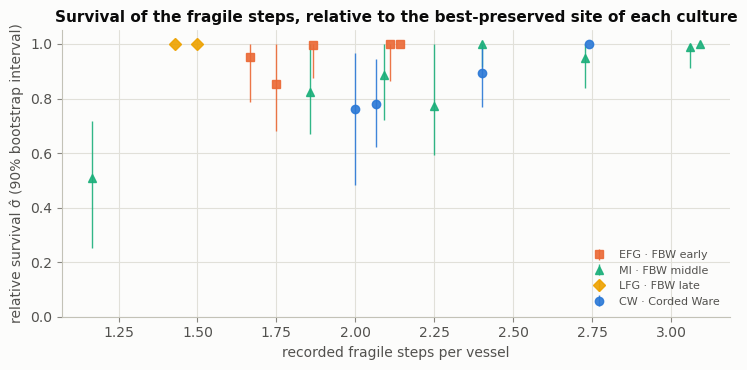

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for c, table in survival_tables.items():
    ax.errorbar(table["fragile steps per vessel"], table["σ̂"],
                yerr=[table["σ̂"] - table["5%"], table["95%"] - table["σ̂"]], fmt=pl.MARKERS[c], color=pl.COLORS[c],
                ms=6, elinewidth=1, capsize=0, label=pl.label(c), alpha=0.9)
ax.set_xlabel("recorded fragile steps per vessel"); ax.set_ylabel("relative survival σ̂ (90% bootstrap interval)")
ax.set_ylim(0, 1.05); ax.legend(fontsize=8, loc="lower right")
ax.set_title("Survival of the fragile steps, relative to the best-preserved site of each culture")
fig.tight_layout(); plt.show()

- **Early and late FBW:** no evidence that sites differ.
- **Middle FBW (megaliths):** the sites differ (p = 0.01). Site 100 records 1.2 fragile steps per vessel, against about 3 at the best sites. Under the model it kept about half of them: $\hat\sigma$ = 0.51, 90 % interval 0.25–0.72.
- **Corded Ware:** pots from barrows carry the most fragile steps (2.7 per vessel). Pots from flat graves and flat-grave cemeteries carry fewer ($\hat\sigma$ ≈ 0.76–0.78, p = 0.005).

**What this does and does not show.** The model explains the differences as loss. But a local habit of decorating less, a different mix of vessel forms, or a different date fit the records just as well. This is Corollary 5(b) at work: a record alone cannot tell "never made" from "made and lost". Strictly, the test shows that sites differ in fragile steps *beyond a shared practice*. Reading that as survival needs data on preservation: surface condition, sherd size, excavation year and recorder.

### 4.5 Which community made this pot, and what is missing?
Proposition 5 gives more than a likelihood. For a gap $u\to w$ in the record:
- the chance that nothing was erased is $P_{uw}\sigma_w/K_{uw}$;
- the expected number of erased visits to $b$ is $D_b(NP)_{ub}K_{bw}/K_{uw}$.

Mixing over communities with weights $p(c\mid y)$ answers both halves of the question at once:
$$p(c,\text{missing}\mid y)=p(c\mid y)\;p(\text{missing}\mid y,c).$$
As an example, take a held-out middle-FBW pot and erase its burnishing. We assume a survival of 0.5 for fragile steps.

In [18]:
def missing_steps(P, sigma, steps):
    """Per gap between consecutive recorded symbols: P(nothing erased) and the expected number of erased
    visits of every technique, E[n_b | y] = D_b (NP)_ub K_bw / K_uw (Proposition 5)."""
    N, K, M = channel(P, sigma)
    y = augment(steps)
    intact = np.array([P[u, w] * sigma[w] / K[u, w] for u, w in zip(y[:-1], y[1:])])
    lost = np.array([(1 - sigma) * (N[u] @ P) * K[:, w] / K[u, w] for u, w in zip(y[:-1], y[1:])])[:, :V]
    return intact, lost

def explain(steps, kernels, prior, s=0.5):
    """p(c | y) under the channel, and the posterior mean number of erased steps per gap, mixed over cultures."""
    post = channel_proba(kernels, prior, [steps], s)[0]
    lost = sum(p * missing_steps(kernels[c], survival(s), steps)[1] for p, c in zip(post, BOKS))
    return post, lost

# a held-out MI vessel (sites of Part 1) whose burnishing has eroded
kernels, prior = kernels_and_prior(train_df)
pot = next(s for s, b in zip(test_df["steps"], y_test) if b == "MI" and "Burnishing" in s)
record = [v for v in pot if v != "Burnishing"]
post_naive = channel_proba(kernels, prior, [record], 1.0)[0]
post, lost = explain(record, kernels, prior)
names = ["START"] + record + ["END"]
print("true chain :", " > ".join(pot))
print("record     :", " > ".join(record))
display(pd.DataFrame({"records taken as complete": post_naive, "channel, σ = 0.5": post}, index=BOKS).T)
top = [(lost[g, b], f"{names[g]} → {names[g + 1]}", vocab[b]) for g in range(lost.shape[0]) for b in range(V)]
pd.DataFrame(sorted(top, reverse=True)[:6], columns=["expected erased", "gap", "missing technique"])

true chain : Wet clay > Modelling > Coiling > Pressure > Application separate element > Wet smoothing > Simple impression > Leather-hard > Burnishing > Dry > Open firing
record     : Wet clay > Modelling > Coiling > Pressure > Application separate element > Wet smoothing > Simple impression > Leather-hard > Dry > Open firing


,CW,EFG,MI,LFG
records taken as complete,0.082,0.334,0.362,0.222
"channel, σ = 0.5",0.050,0.305,0.362,0.283


,expected erased,gap,missing technique
0,0.754,Leather-hard → Dry,Burnishing
1,0.112,Wet smoothing → Simple impression,Simple incision
2,0.083,Application separate element → Wet smoothing,Scraping
3,0.048,Open firing → END,Smudging
4,0.038,Leather-hard → Dry,Shining
5,0.016,Simple impression → Leather-hard,Simple incision


**How to read it.**
- *First table:* the BoK posterior of the eroded record, either taken as complete or with the channel ($\sigma=0.5$). The channel moves probability away from CW (0.08 → 0.05) and early FBW toward late FBW. The true BoK, middle FBW, stays at 0.36.
- *Second table:* the six largest posterior expected numbers of erased steps, by gap and technique, mixed over the BoKs. These are expected counts; since a gap rarely hides more than one step, they act as probabilities. Burnishing in the leather-hard → dry gap (0.75) dominates; every other candidate is below 0.12.

The channel points to the right gap and the right technique: burnishing between leather-hard and dry, with expected count 0.75. The attribution stays uncertain (middle FBW 0.36 either way): the pot is ambiguous with or without its burnishing.

**How often is the missing step found?** In every held-out pot with at least one fragile step, erase one fragile step at random. Then rank all (gap, technique) pairs by their expected count, and see where the true one lands.

In [19]:
rows, rng = [], np.random.default_rng(SEED)
for seed in range(3):
    for tr, te in ev.splits(df, "site", 5, seed):
        train, test = df.iloc[tr], df.iloc[te]
        kernels, prior = kernels_and_prior(train)
        pooled = markov_kernel(train["steps"])
        freq = Counter(v for s in train["steps"] for v in s if v in FRAGILE)
        for steps, c_true in zip(test["steps"], test["bok"].astype(str)):
            f = [i for i, v in enumerate(steps) if v in FRAGILE]
            if not f:
                continue
            i = rng.choice(f)
            record, truth = steps[:i] + steps[i + 1:], (i, idx[steps[i]])        # gap i of the record, technique
            post, lost_mix = explain(record, kernels, prior)
            cands = {"mixture over cultures, p(c | record)": lost_mix,
                     "true culture (oracle)": missing_steps(kernels[c_true], survival(0.5), record)[1],
                     "pooled practice, no culture": missing_steps(pooled, survival(0.5), record)[1]}
            for name, lost in cands.items():
                order = np.argsort(-lost, axis=None)
                gap_rank = list(zip(*np.unravel_index(order, lost.shape))).index(truth)
                tech_rank = list(np.argsort(-lost.sum(0))).index(truth[1])
                rows.append({"model": name, "gap + technique, top 1": gap_rank < 1, "gap + technique, top 3": gap_rank < 3,
                             "technique, top 1": tech_rank < 1, "technique, top 3": tech_rank < 3})
            ranked = [idx[v] for v, _ in freq.most_common()]
            rows.append({"model": "most frequent fragile techniques (no position)",
                         "technique, top 1": ranked.index(truth[1]) < 1 if truth[1] in ranked else False,
                         "technique, top 3": ranked.index(truth[1]) < 3 if truth[1] in ranked else False})
recovery = pd.DataFrame(rows).groupby("model", sort=False).mean()
print(f"{len(rows) // 4} held-out vessels with one fragile step erased (sites held out, 3 × 5-fold)")
recovery

768 held-out vessels with one fragile step erased (sites held out, 3 × 5-fold)


,"gap + technique, top 1","gap + technique, top 3","technique, top 1","technique, top 3"
model,,,,
"mixture over cultures, p(c | record)",0.59,0.842,0.618,0.885
true culture (oracle),0.591,0.846,0.608,0.888
"pooled practice, no culture",0.596,0.836,0.618,0.862
most frequent fragile techniques (no position),NaN,NaN,0.426,0.733


**How to read it.**
- *Columns:* the share of trials in which the erased step is ranked first, or among the top 3, either as gap and technique jointly or as technique only. NaN means not applicable: the frequency baseline has no notion of position.
- *Evidence:* 768 trials = 256 vessels × 3 seeds, with a different step erased in each seed. One standard error is ≈ 0.03 (binomial, 256 vessels). The three model rows differ by ≤ 0.03, so they do not really differ. All beat the frequency baseline by 0.15–0.19.

- **Gap and technique.** The erased step is found at the first guess for 59 % of pots, and within three guesses for 84 %.
- **Technique alone.** 62 % and 89 %, against 43 % and 73 % for simply guessing the most frequent fragile techniques.
- **The community does not help.** Knowing the true community is no better than the pooled practice. *Where* a step can be missing is fixed by the shared grammar of the craft (burnishing between leather-hard and dry, decoration after smoothing), not by the community.

## 5 · Geography
Where a pot was found is information the chain does not contain. Two questions: is it *separate* information, and how much is it worth?

### 5.1 Do nearby pots share chains beyond their community?
If chains varied smoothly in space within a community, place and chain would partly repeat each other. The test is a Mantel test (Mantel 1967):
- for every pair of pots from *different* sites, compute the chain distance (1 − Jaccard similarity of their sets of transitions) and the great-circle distance;
- correlate the two (Spearman);
- judge the correlation against 999 permutations of the site locations, which keep the pots of each site together.

In [20]:
def haversine(lat1, lon1, lat2, lon2):
    """Great-circle distance in km."""
    r = np.pi / 180
    a = np.sin((lat2 - lat1) * r / 2) ** 2 + np.cos(lat1 * r) * np.cos(lat2 * r) * np.sin((lon2 - lon1) * r / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

edges = df["steps"].map(lambda s: set(zip(s[:-1], s[1:])))
rows, rng = [], np.random.default_rng(SEED)
for c in BOKS + ["all"]:
    sub = df.dropna(subset=["latitude"])
    sub = sub if c == "all" else sub[sub["bok"] == c]
    E, site = sub.index.to_numpy(), sub["site_id"].to_numpy()
    i, j = np.triu_indices(len(sub), 1)
    keep = site[i] != site[j]                                    # pairs from different sites only
    i, j = i[keep], j[keep]
    d_chain = np.array([1 - len(edges[E[a]] & edges[E[b]]) / len(edges[E[a]] | edges[E[b]]) for a, b in zip(i, j)])
    coords = sub.groupby("site_id")[["latitude", "longitude"]].first()
    def rho(perm):
        xy = coords.loc[perm[site]].to_numpy()
        return spearmanr(d_chain, haversine(xy[i, 0], xy[i, 1], xy[j, 0], xy[j, 1])).correlation
    ids = coords.index.to_numpy()
    obs = rho(pd.Series(ids, index=ids))
    null = np.array([rho(pd.Series(rng.permutation(ids), index=ids)) for _ in range(999)])
    rows.append({"culture": pl.label(c) if c != "all" else "all vessels", "vessels": len(sub), "sites": len(ids),
                 "Spearman ρ (chain distance, km)": obs, "p (999 site permutations)": (1 + np.sum(null >= obs)) / 1000})
pd.DataFrame(rows).set_index("culture")

,vessels,sites,"Spearman ρ (chain distance, km)",p (999 site permutations)
culture,,,,
CW · Corded Ware,86,62,0.017,0.216
EFG · FBW early,62,8,-0.061,0.838
MI · FBW middle,95,14,0.003,0.475
LFG · FBW late,30,7,-0.356,0.968
all vessels,273,85,0.060,0.030


**How to read it.**
- *ρ:* the Spearman correlation between chain distance and geographic distance, over pairs of vessels from different sites.
- *p:* the share of 999 random reassignments of locations to sites that give a $\rho$ at least as large (one-sided: it tests distance decay).
- *Late FBW:* its $\rho=-0.36$ (p = 0.97) is *anti*-decay — nearby late-FBW vessels differ more — but it rests on 7 sites, i.e. 21 pairs of sites.

- **Within every community** the correlation is null (p ≥ 0.2): there is no sign that chains drift with distance.
- **Over all pots** the correlation is weak but significant (ρ = 0.06, p = 0.03), because the communities themselves lived in different places.

So, given the community, there is no sign of dependence between chain and place, $X\perp Z\mid C$, and the two pieces of evidence can be multiplied. The tests have little power with 7–14 sites per FBW phase, so this supports the assumption without proving it.

### 5.2 A spatial prior
Define $p(c\mid z)$ at a location $z$ as the Gaussian-kernel mass of each community's training pots around $z$. The bandwidth is chosen by leaving one training site out at a time. With $X\perp Z\mid C$,
$$p(c\mid x,z)\propto p(x\mid c)\;p(c\mid z),$$
with $p(x\mid c)$ the first-order Markov model of the main notebook. Whole sites are held out, so the prior for a new site comes only from *other* sites nearby.

In [21]:
def kde_prior(train, test, h_grid=(5, 10, 20, 40, 80)):
    """p(c | location): Gaussian-kernel mass of each culture's training vessels around the location (+ a small floor);
    bandwidth h (km) chosen by leave-one-site-out log-likelihood on the training vessels. No coordinates → marginal."""
    tr = train.dropna(subset=["latitude"])
    lat, lon, cul, sid = (tr[k].to_numpy() for k in ["latitude", "longitude", "bok", "site_id"])
    cul = cul.astype(str)
    def at(la, lo, h, exclude=None):
        w = np.exp(-0.5 * (haversine(la, lo, lat, lon) / h) ** 2) * (sid != exclude)
        p = np.array([w[cul == c].sum() for c in BOKS]) + 1e-3
        return p / p.sum()
    def loo(h):
        return sum(np.log(at(g["latitude"].iloc[0], g["longitude"].iloc[0], h, s)[[BOKS.index(b) for b in g["bok"].astype(str)]]).sum()
                   for s, g in tr.groupby("site_id"))
    h = max(h_grid, key=loo)
    marg = train["bok"].astype(str).value_counts().reindex(BOKS).to_numpy() + 1.0
    marg = marg / marg.sum()
    return np.array([at(la, lo, h) if np.isfinite(la) else marg for la, lo in zip(test["latitude"], test["longitude"])]), h

geo_models = ["Markov order 1", "geography only", "Markov × geography"]
bandwidths, pooled = [], {m: [] for m in geo_models}
for seed in range(3):
    full = {m: np.zeros((len(df), len(BOKS))) for m in geo_models}
    for tr, te in ev.splits(df, "site", 5, seed):
        train, test = df.iloc[tr], df.iloc[te]
        G, h = kde_prior(train, test); bandwidths.append(h)
        mk = clf.MarkovClassifier(1, beta=2.0, grammar=grammar).fit(train)      # the Markov model of the main notebook
        L = mk.loglik(test); L = np.where(np.isfinite(L), L, -1e9)
        full["Markov order 1"][te] = mk.predict_proba(test)
        full["geography only"][te] = G
        full["Markov × geography"][te] = softmax_rows(L + np.log(G))
    for m, p in full.items():
        pooled[m].append(p)
for m in geo_models:
    R.add(m, "CV, sites", np.tile(y_bok, 3), np.vstack(pooled[m]))
print("bandwidths chosen (km):", dict(Counter(bandwidths)))
R.table("CV, sites", geo_models)[["accuracy", "balanced_acc", "macro_F1", "log_loss", "ECE"]]

bandwidths chosen (km): {20: 14, 10: 1}


,,accuracy,balanced_acc,macro_F1,log_loss,ECE
model,protocol,,,,,
Markov order 1,"CV, sites",0.537,0.459,0.456,1.292,0.128
geography only,"CV, sites",0.577,0.470,0.441,1.166,0.139
Markov × geography,"CV, sites",0.636,0.531,0.526,1.164,0.103


**How to read it.**
- *Printed line:* the bandwidth of the spatial prior chosen in each of the 15 training folds: 20 km in 14 of them, 10 km in one.
- *Table:* sites held out, 3 × 5-fold.
- *Evidence (paired site bootstrap, end of Part 7):* combining place with the chain changes accuracy by +0.10 ± 0.04 ($z$ = 2.7) relative to the chain alone. The difference between place alone (0.58) and the chain alone (0.54) is within noise.

Place alone (0.58) beats the chain alone (0.54). Together they reach 0.64, with the lowest log-loss of the three. The two kinds of evidence add up, as $X\perp Z\mid C$ suggests, but less than the sum of their separate gains over the majority baseline: communities that lived in the same area blur the spatial prior.

## 6 · The bridge: one maximum-entropy family
Parts 2–5 spoke four languages: topic models, selection, Markov chains and geography. They meet in one family of distributions.

Maximum entropy says: among all distributions that reproduce what you know (some averages), take the one that assumes nothing else. It always has the form $\exp(\lambda\cdot\text{features})/Z$ (Jaynes 1957). Over whole chains this is Maximum Caliber (Part 3). Over the labels of a given pot it is the maximum-entropy classifier (Berger, Della Pietra & Della Pietra 1996).

### 6.1 Two propositions
**Proposition 6 (survival is a force).** Let the practice of community $c$ be $P_c(\Gamma)\propto Q(\Gamma)\,e^{\mu_c\cdot A(\Gamma)}$, as in Part 3. Let survival be log-linear in the same features, $s(\Gamma)=e^{\eta\cdot A(\Gamma)}$ with $\eta\le0$. For example, $A_v$ counts technique $v$, each occurrence survives with probability $\sigma_v$, and $\eta_v=\ln\sigma_v$ (the token survival of 2.3). Then
$$P_c(\Gamma\mid S=1)\propto Q(\Gamma)\,e^{(\mu_c+\eta)\cdot A(\Gamma)},$$
and:
- (a) MaxCal fitted to survivors returns $\mu_c+\eta$, not $\mu_c$;
- (b) the differences $\mu_c-\mu_{c'}$, and attribution, do not depend on $\eta$;
- (c) $\mu_c$ itself needs $\eta$ from outside the data.

*Proof.*
- (a) $s(\Gamma)P_c(\Gamma)=Q(\Gamma)\,e^{(\mu_c+\eta)\cdot A(\Gamma)}/Z_c$. Renormalising changes the constant, not the form.
- (b) In $p(c\mid\Gamma,S=1)\propto p(c\mid S=1)\,P_c(\Gamma\mid S=1)$, the factor $Q(\Gamma)e^{\eta\cdot A(\Gamma)}$ is common to all $c$ and cancels; so does $\eta$ in $(\mu_c+\eta)-(\mu_{c'}+\eta)$.
- (c) $(\mu_c,\eta)$ and $(\mu_c+\delta,\eta-\delta)$ produce the same survivors (Proposition 3). $\square$

This is Proposition 1 and the Theorem of 2.3 in the language of physics: survival is an external field that shifts every community's forces by the same amount. Part 4 is different. Losing a *pot* tilts the distribution of chains; losing a *step* changes the chain itself, and leads to a marginalisation (Proposition 5), not a tilt.

**Proposition 7 (Markov attribution is a maximum-entropy classifier).** Let each community's chains be first-order Markov. Let $n_{ab}(x)$ be the number of transitions $a\to b$ in $x$, START and END included. Then
$$\ln p(c\mid x)=\ln\pi_c+\sum_{a,b}n_{ab}(x)\,\theta_{c,ab}-\ln Z(x),\qquad\theta_{c,ab}=\ln P_c(b\mid a).$$
This is the log-linear form of the maximum-conditional-entropy model whose constraints are the class-wise expected transition counts.

*Proof.* $\ln p(x\mid c)=\sum_t\ln P_c(x_{t+1}\mid x_t)=\sum_{a,b}n_{ab}(x)\ln P_c(b\mid a)$. Apply Bayes' rule, with $Z(x)=\sum_c\pi_c\,p(x\mid c)$. $\square$

Kroon's grammar makes each next step depend on the whole history (no repeated techniques, the hydric state). The identity is therefore checked on the Markov model without the grammar.

In [22]:
def transitions(steps):
    p = [START] + list(steps) + [END]
    return Counter(f"{a}→{b}" for a, b in zip(p[:-1], p[1:]))

models = {c: markov.MarkovChain(1, beta=2.0, alpha=0.5, vocab=vocab).fit(groups[c]) for c in BOKS}   # no grammar
log_prior = np.log(df["bok"].value_counts(normalize=True).reindex(BOKS).to_numpy())
feats = sorted({k for s in df["steps"] for k in transitions(s)})
theta = np.array([[np.log(models[c].dist([] if a == START else [a])[b]) for a, b in (f.split("→") for f in feats)]
                  for c in BOKS])                                             # θ_c,ab = log P_c(b | a)
n_x = np.array([[transitions(s).get(f, 0) for f in feats] for s in df["steps"]])
linear = softmax_rows(n_x @ theta.T + log_prior)
bayes = softmax_rows(np.array([[models[c].logprob(s) for c in BOKS] for s in df["steps"]]) + log_prior)
print(f"{len(feats)} transition features; max |log-linear posterior − Markov–Bayes posterior| = {np.abs(linear - bayes).max():.1e}")
assert np.allclose(linear, bayes, atol=1e-12)

56 transition features; max |log-linear posterior − Markov–Bayes posterior| = 8.3e-16


**So what?** The generative Markov model sets $\theta$ by counting within each community. The maximum-entropy classifier fits the same $\theta$ to tell the communities apart, with a Gaussian prior that holds back over-confidence. Any other evidence is just another constraint, that is, another block of features:
- geography: 8 Gaussian bumps of 20 km centred on training sites;
- vessel form;
- find context.

No independence between the blocks has to be assumed; the fitted weights take care of it.

### 6.2 The maximum-entropy classifier
This is multinomial logistic regression with an L2 penalty, equivalent to a Gaussian prior on $\theta$ (Chen & Rosenfeld 2000). The penalty's strength is chosen inside each training fold, by 5-fold cross-validated log-loss.

In [23]:
def rbf(train, part, k=8, h=20.0):
    """Geography as k Gaussian bumps (width h km) centred on training sites spread by farthest-point sampling."""
    pts = train.dropna(subset=["latitude"]).drop_duplicates("site_id")[["latitude", "longitude"]].to_numpy()
    centres = [pts[0]]
    for _ in range(k - 1):
        d = np.min([haversine(pts[:, 0], pts[:, 1], *c) for c in centres], axis=0)
        centres.append(pts[d.argmax()])
    return np.nan_to_num(np.column_stack([np.exp(-0.5 * (haversine(part["latitude"].to_numpy(), part["longitude"].to_numpy(), *c) / h) ** 2)
                                          for c in centres]))

def features(train, part, blocks):
    X_ = []
    if "transitions" in blocks:
        names = sorted({k for s in train["steps"] for k in transitions(s)})
        X_.append(np.array([[transitions(s).get(f, 0) for f in names] for s in part["steps"]], float))
    if "geography" in blocks:
        X_.append(rbf(train, part))
    for col, block in [("vessel_type", "form"), ("site_type", "context")]:
        if block in blocks:
            cats = sorted(train[col].dropna().unique())
            X_.append(np.array([[float(v == c) for c in cats] for v in part[col]]))
    return np.hstack(X_)

class MaxEnt:
    """Multinomial logistic regression = maximum conditional entropy under feature constraints; Gaussian prior
    (L2) on θ, its strength chosen by inner 5-fold cross-validated log-loss on the training vessels."""
    def __init__(self, blocks, seed=0):
        self.blocks, self.seed = blocks, seed
    def fit(self, train):
        self.train = train
        cv = StratifiedKFold(5, shuffle=True, random_state=self.seed)
        self.model = GridSearchCV(LogisticRegression(max_iter=5000), {"C": [0.03, 0.1, 0.3, 1, 3, 10]},
                                  scoring="neg_log_loss", cv=cv).fit(features(train, train, self.blocks),
                                                                     train["bok"].astype(str))
        return self
    def predict_proba(self, part):
        p = self.model.predict_proba(features(self.train, part, self.blocks))
        return p[:, [list(self.model.classes_).index(c) for c in BOKS]]

maxent_sets = {"MaxEnt: transitions": ("transitions",),
               "MaxEnt: geography": ("geography",),
               "MaxEnt: transitions + geography": ("transitions", "geography"),
               "MaxEnt: transitions + geography + form": ("transitions", "geography", "form"),
               "MaxEnt: + find context": ("transitions", "geography", "form", "context")}
for split_name, scheme in [("sites", "site"), ("vessels", "stratified")]:
    for name, blocks in maxent_sets.items():
        probas = [ev.cross_val_proba(df, lambda: MaxEnt(blocks, seed), scheme, 5, seed) for seed in range(3)]
        R.add(name, f"CV, {split_name}", np.tile(y_bok, 3), np.vstack(probas))
cols = ["accuracy", "balanced_acc", "macro_F1", "log_loss", "ECE"]
pd.concat({s: R.table(f"CV, {s}", list(maxent_sets))[cols].droplevel("protocol") for s in ["sites", "vessels"]}, axis=1)

sites                        \
                                       accuracy balanced_acc macro_F1   
model                                                                   
MaxEnt: transitions                       0.537        0.456    0.456   
MaxEnt: geography                         0.577        0.486    0.482   
MaxEnt: transitions + geography           0.659        0.558    0.556   
MaxEnt: transitions + geography + form    0.688        0.598    0.599   
MaxEnt: + find context                    0.767        0.642    0.641   

                                                        vessels               \
                                       log_loss    ECE accuracy balanced_acc   
model                                                                          
MaxEnt: transitions                       1.040  0.056    0.591        0.547   
MaxEnt: geography                         1.278  0.132    0.716        0.674   
MaxEnt: transitions + geography           0.967  0.095    0.783        0.747   
MaxEnt: transitions + geography + form    0.820  0.072    0.783        0.745   
MaxEnt: + find context                    0.594  0.099    0.895        0.844   

                                                                 
                                       macro_F1 log_loss    ECE  
model                                                            
MaxEnt: transitions                       0.561    0.971  0.054  
MaxEnt: geography                         0.705    0.704  0.140  
MaxEnt: transitions + geography           0.758    0.605  0.050  
MaxEnt: transitions + geography + form    0.753    0.582  0.033  
MaxEnt: + find context                    0.849    0.314  0.019

**How to read it.**
- *Layout:* rows add blocks of features; the left block holds out sites, the right block vessels (3 × 5-fold).
- *Evidence (paired site bootstrap, end of Part 7):*
  - with transitions alone, MaxEnt and Markov differ by 0.00 ± 0.01, while the log-loss drops by 0.25 ± 0.09 ($z$ = −2.9): the same decisions, better probabilities in accuracy;
  - adding geography gives +0.12 ± 0.04 ($z$ = 2.9);
  - transitions + geography + form beats the Markov chain by +0.15 ± 0.04 ($z$ = 3.9) and vessel form alone by +0.13 ± 0.05 ($z$ = 2.6);
  - adding the find context gives +0.08 ± 0.05 ($z$ = 1.6), suggestive but not conclusive; its log-loss gain (0.23 ± 0.10) is clearer.
- *Caveat:* "vessels held out" scores are inflated by site-mates in the training data (geography alone 0.72 vs 0.58).

- **Transitions alone:** the same accuracy as the Markov model (0.54), but much better calibrated (log-loss 1.04 vs 1.29; ECE 0.06 vs 0.13). Fitting to discriminate, with a prior, beats counting.
- **+ geography:** 12 more points (0.66).
- **+ form:** 3 more (0.69, log-loss 0.82). This is above every chain-only model and close to the chain-only ceiling of 0.73. That ceiling no longer binds, because the evidence is no longer only the chain.
- **+ find context:** 0.77. The caveats of 2.5 apply: if phases were assigned partly by context, this is circular, and context says nothing about *how* the pots were made.
- **Vessels held out instead of sites:** geography looks better than it is (0.72 alone), because pots from the same site are in the training data. Holding out sites is the honest test for a pot from a new excavation.

## 7 · Answers
All attribution models of this notebook, scored the same way. The bars are coloured by the evidence they use:
- light grey: baselines;
- dark grey: the chain alone;
- green: place alone;
- blue: chain + place (+ form);
- orange: the find context as well.

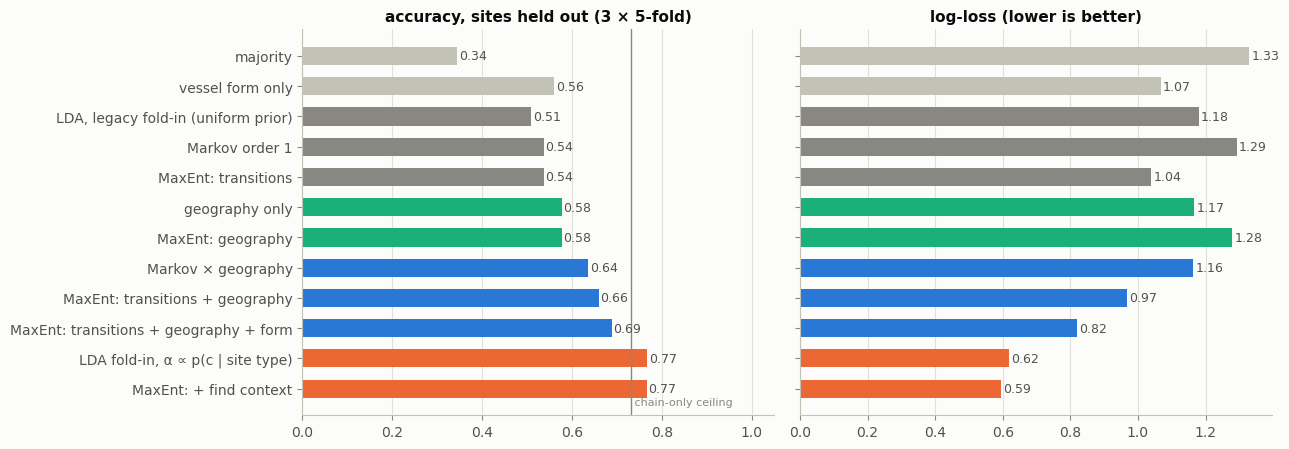

,accuracy,balanced_acc,macro_F1,log_loss,ECE
model,,,,,
majority,0.344,0.250,0.128,1.329,4.404e-04
vessel form only,0.560,0.457,0.427,1.068,4.023e-02
"LDA, legacy fold-in (uniform prior)",0.510,0.524,0.486,1.180,8.520e-02
Markov order 1,0.537,0.459,0.456,1.292,1.282e-01
MaxEnt: transitions,0.537,0.456,0.456,1.040,5.615e-02
geography only,0.577,0.470,0.441,1.166,1.394e-01
MaxEnt: geography,0.577,0.486,0.482,1.278,1.315e-01
Markov × geography,0.636,0.531,0.526,1.164,1.027e-01
MaxEnt: transitions + geography,0.659,0.558,0.556,0.967,9.519e-02


In [24]:
for name, make in [("majority", clf.Majority), ("vessel form only", lambda: clf.ColumnPrior("vessel_type"))]:
    R.add(name, "CV, sites", np.tile(y_bok, 3), np.vstack([ev.cross_val_proba(df, make, "site", 5, s) for s in range(3)]))
final = [("majority", pl.INK["axis"]), ("vessel form only", pl.INK["axis"]),
         ("LDA, legacy fold-in (uniform prior)", pl.INK["muted"]), ("Markov order 1", pl.INK["muted"]),
         ("MaxEnt: transitions", pl.INK["muted"]),
         ("geography only", pl.COLORS["MI"]), ("MaxEnt: geography", pl.COLORS["MI"]),
         ("Markov × geography", pl.COLORS["CW"]), ("MaxEnt: transitions + geography", pl.COLORS["CW"]),
         ("MaxEnt: transitions + geography + form", pl.COLORS["CW"]),
         ("LDA fold-in, α ∝ p(c | site type)", pl.COLORS["EFG"]), ("MaxEnt: + find context", pl.COLORS["EFG"])]
t = R.table("CV, sites", [m for m, _ in final]).droplevel("protocol")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
pl.hbars(axes[0], t.index, t["accuracy"].values, [c for _, c in final],
         ref=ceiling["BoK (4 classes)"], ref_label="chain-only ceiling")
pl.hbars(axes[1], t.index, t["log_loss"].values, [c for _, c in final])
axes[0].set_xlim(0, 1.05); axes[0].set_title("accuracy, sites held out (3 × 5-fold)")
axes[1].set_title("log-loss (lower is better)"); axes[1].set_yticklabels([])
fig.tight_layout(); plt.show()
t[["accuracy", "balanced_acc", "macro_F1", "log_loss", "ECE"]]

**How large is the noise?** Vessels of one site resemble each other, so the honest uncertainty comes from resampling *sites*. We draw the sites with replacement 2000 times and recompute every score; the spread of the recomputed values is the standard error (se). For a difference between two models, both are scored on the same draws, which removes the variation they share. $z$ = difference / se; $|z|\gtrsim2$ is a difference beyond noise.

In [25]:
def site_bootstrap(models, pairs=(), protocol="CV, sites", B=2000, seed=SEED):
    """Uncertainty of cross-validated scores when whole sites are resampled with replacement (the vessels of a site
    move together). Each vessel's hit (0/1) and −ln p(true BoK) are first averaged over the 3 seeds. Paired
    differences use the same draws for both models."""
    names = list(dict.fromkeys(list(models) + [m for pair in pairs for m in pair]))
    y_idx = np.array([BOKS.index(c) for c in y_bok])
    hit, nll = {}, {}
    for m in names:
        p = R.proba[(m, protocol)][1].reshape(-1, len(df), len(BOKS))          # seeds × vessels × BoKs
        hit[m] = (p.argmax(2) == y_idx).mean(0)
        nll[m] = -np.log(np.clip(p[:, np.arange(len(df)), y_idx], 1e-6, 1)).mean(0)
    sites = list(df.groupby("site_id").indices.values())
    rng = np.random.default_rng(seed)
    draws = [np.concatenate([sites[k] for k in rng.integers(len(sites), size=len(sites))]) for _ in range(B)]
    se = lambda v: np.std([v[d].mean() for d in draws])
    single = pd.DataFrame({("accuracy", "mean"): {m: hit[m].mean() for m in models},
                           ("accuracy", "se"): {m: se(hit[m]) for m in models},
                           ("log-loss", "mean"): {m: nll[m].mean() for m in models},
                           ("log-loss", "se"): {m: se(nll[m]) for m in models}})
    paired = pd.DataFrame({f"{a}  −  {b}": {("Δ accuracy", "mean"): (hit[a] - hit[b]).mean(),
                                             ("Δ accuracy", "se"): se(hit[a] - hit[b]),
                                             ("Δ accuracy", "z"): (hit[a] - hit[b]).mean() / se(hit[a] - hit[b]),
                                             ("Δ log-loss", "mean"): (nll[a] - nll[b]).mean(),
                                             ("Δ log-loss", "se"): se(nll[a] - nll[b])} for a, b in pairs}).T
    return single, paired

single, paired = site_bootstrap([m for m, _ in final], [
    ("LDA fold-in, α ∝ survivor proportions", "LDA, legacy fold-in (uniform prior)"),
    ("   + prior shift per site (EM)", "LDA Bayes rule, survivor prior, τ = 1/3"),
    ("LDA fold-in, α ∝ p(c | site type)", "LDA, legacy fold-in (uniform prior)"),
    ("MaxEnt: transitions", "Markov order 1"),
    ("Markov × geography", "Markov order 1"),
    ("MaxEnt: transitions + geography", "MaxEnt: transitions"),
    ("MaxEnt: transitions + geography + form", "Markov order 1"),
    ("MaxEnt: transitions + geography + form", "vessel form only"),
    ("MaxEnt: + find context", "MaxEnt: transitions + geography + form")])
print(f"{df['site_id'].nunique()} sites, 2000 bootstrap draws")
display(single.round(3))
paired.round(3)

88 sites, 2000 bootstrap draws


accuracy        log-loss       
                                           mean     se     mean     se
majority                                  0.344  0.082    1.329  0.073
vessel form only                          0.560  0.049    1.068  0.060
LDA, legacy fold-in (uniform prior)       0.510  0.041    1.180  0.051
Markov order 1                            0.537  0.044    1.292  0.135
MaxEnt: transitions                       0.537  0.043    1.040  0.067
geography only                            0.577  0.075    1.166  0.165
MaxEnt: geography                         0.577  0.076    1.278  0.243
Markov × geography                        0.636  0.056    1.164  0.169
MaxEnt: transitions + geography           0.659  0.059    0.967  0.152
MaxEnt: transitions + geography + form    0.688  0.052    0.820  0.110
LDA fold-in, α ∝ p(c | site type)         0.768  0.045    0.619  0.076
MaxEnt: + find context                    0.767  0.055    0.594  0.138

Δ accuracy  \
                                                                                    mean   
LDA fold-in, α ∝ survivor proportions  −  LDA, legacy fold-in (uniform prior)      0.021   
   + prior shift per site (EM)  −  LDA Bayes rule, survivor prior, τ = 1/3         0.007   
LDA fold-in, α ∝ p(c | site type)  −  LDA, legacy fold-in (uniform prior)          0.258   
MaxEnt: transitions  −  Markov order 1                                            -0.000   
Markov × geography  −  Markov order 1                                              0.099   
MaxEnt: transitions + geography  −  MaxEnt: transitions                            0.122   
MaxEnt: transitions + geography + form  −  Markov order 1                          0.151   
MaxEnt: transitions + geography + form  −  vessel form only                        0.128   
MaxEnt: + find context  −  MaxEnt: transitions + geography + form                  0.079   

                                                                                      \
                                                                                  se   
LDA fold-in, α ∝ survivor proportions  −  LDA, legacy fold-in (uniform prior)  0.016   
   + prior shift per site (EM)  −  LDA Bayes rule, survivor prior, τ = 1/3     0.019   
LDA fold-in, α ∝ p(c | site type)  −  LDA, legacy fold-in (uniform prior)      0.062   
MaxEnt: transitions  −  Markov order 1                                         0.011   
Markov × geography  −  Markov order 1                                          0.036   
MaxEnt: transitions + geography  −  MaxEnt: transitions                        0.042   
MaxEnt: transitions + geography + form  −  Markov order 1                      0.039   
MaxEnt: transitions + geography + form  −  vessel form only                    0.049   
MaxEnt: + find context  −  MaxEnt: transitions + geography + form              0.050   

                                                                                      \
                                                                                   z   
LDA fold-in, α ∝ survivor proportions  −  LDA, legacy fold-in (uniform prior)  1.289   
   + prior shift per site (EM)  −  LDA Bayes rule, survivor prior, τ = 1/3     0.384   
LDA fold-in, α ∝ p(c | site type)  −  LDA, legacy fold-in (uniform prior)      4.144   
MaxEnt: transitions  −  Markov order 1                                        -0.000   
Markov × geography  −  Markov order 1                                          2.726   
MaxEnt: transitions + geography  −  MaxEnt: transitions                        2.899   
MaxEnt: transitions + geography + form  −  Markov order 1                      3.894   
MaxEnt: transitions + geography + form  −  vessel form only                    2.621   
MaxEnt: + find context  −  MaxEnt: transitions + geography + form              1.578   

                                                                              Δ log-loss  \
                                                                                    mean   
LDA fold-in, α ∝ survivor proportions  −  LDA, legacy fold-in (uniform prior)     -0.057   
   + prior shift per site (EM)  −  LDA Bayes rule, survivor prior, τ = 1/3        -0.037   
LDA fold-in, α ∝ p(c | site type)  −  LDA, legacy fold-in (uniform prior)         -0.561   
MaxEnt: transitions  −  Markov order 1                                            -0.252   
Markov × geography  −  Markov order 1                                             -0.128   
MaxEnt: transitions + geography  −  MaxEnt: transitions                           -0.073   
MaxEnt: transitions + geography + form  −  Markov order 1                         -0.472   
MaxEnt: transitions + geography + form  −  vessel form only                       -0.248   
MaxEnt: + find context  −  MaxEnt: transitions + geography + form                 -0.227   

                                                                                      
                           

**How to read it.**
- *First table:* each model's cross-validated accuracy and log-loss with its site-bootstrap standard error (88 sites). Accuracies carry ± 0.04–0.08. The majority rule's own ± 0.08 shows how much the class mix varies from site to site.
- *Second table:* paired differences.
  - **Beyond noise** ($|z|>2$):
    - the site-type prior over plain LDA (+0.26, $z$ = 4.1);
    - place added to the chain, in either model (+0.10 and +0.12, $z$ = 2.7–2.9);
    - transitions + place + form over the Markov chain (+0.15, $z$ = 3.9) and over form alone (+0.13, $z$ = 2.6).
  - **Within noise:**
    - the survivor prior (+0.02) and the per-site prior shift (+0.01);
    - MaxEnt vs Markov on transitions alone (0.00), although MaxEnt's log-loss is clearly better (−0.25, $z$ = −2.9);
    - the find context on top of transitions + place + form (+0.08, $z$ = 1.6).
- *Caveat:* sites are resampled as if independent. Neighbouring sites may share more than that, so these standard errors are, if anything, too small.

**Which community made this pot?** Put all the evidence into one log-linear model. With sites held out:

| evidence used | accuracy |
|---|---|
| the chain alone (any model) | ≈ 0.54 |
| + place | 0.66 |
| + form | 0.69 |
| + find context | 0.77 |

The topic models are not the bottleneck; the information is. Report the probabilities, not just the label: the maximum-entropy model is the best calibrated.

**What is missing from its sequence?** There are two cases.
- A *broken* pot (its end is missing) is censoring: score the prefix by its marginal likelihood (main notebook, 10.5).
- An *eroded* pot (steps missing inside) is a deletion channel. The record is still Markov, with $K=(I-PD)^{-1}PS$, and the posterior over erased steps in each gap finds the right step in the right place at the first guess for 59 % of pots, and within three guesses for 84 %.

**How to deal with missing, historical and survival data?**
1. **Write down the mechanism (4.1).** Say which units are lost (pots, steps, chain ends) and what the loss depends on.
2. **MCAR and MAR losses** (broken ends; recording differences explained by excavation metadata): condition on what is observed and integrate out the rest. The mechanism can then be ignored.
3. **MNAR losses** (selective survival of pots; erosion of steps): model them. Attribution is protected (Propositions 1 and 6). Statements about the population — what potters actually did, how many pots each community made — need an outside estimate of survival (Proposition 3, Corollary 5).
4. **Historical collections:** record the excavation era, the recorder and the state of preservation as covariates. Site-level survival then becomes MAR given them, and the EM of 4.4 can share strength across sites with the same conditions.
5. **Do not bootstrap to create data.** Resampling measures uncertainty; it adds no information.

**The proposed HMM** (hidden: the pot as made; intermediate: the pot that survived; observed: the record) is exactly Parts 2 and 4 together. The pot-level step is a selection (a tilt); the step-level step is a deletion channel. Its transitions can be estimated per site (4.4), but only *relative to a reference* site, and the site effect is confounded with local practice. Data on preservation are what would make it identifiable.

**Next steps.**
1. Record preservation (surface condition, sherd size) and excavation metadata for every vessel.
2. Build a hierarchical model: community practice → site practice (with shrinkage), plus site survival, fitted with the EM of 4.4.
3. Fit MaxCal with community forces and a common survival field (Proposition 6), jointly with the classifier.
4. Add radiocarbon dates as a further feature block.
5. Validate on ethnographic data where the community is known.

### References (new in this notebook; those of Parts 2–3 are listed in the main notebook)
- Baum, Petrie, Soules & Weiss (1970). A maximization technique occurring in the statistical analysis of probabilistic functions of Markov chains. *Ann. Math. Statist.* 41: 164–171.
- Berger, Della Pietra & Della Pietra (1996). A maximum entropy approach to natural language processing. *Computational Linguistics* 22: 39–71.
- Chen & Rosenfeld (2000). A survey of smoothing techniques for ME models. *IEEE Trans. Speech Audio Process.* 8: 37–50.
- Dempster, Laird & Rubin (1977). Maximum likelihood from incomplete data via the EM algorithm. *J. R. Stat. Soc. B* 39: 1–38.
- Jaynes (1957). Information theory and statistical mechanics. *Phys. Rev.* 106: 620–630.
- Little & Rubin (2019). *Statistical Analysis with Missing Data*, 3rd ed. Wiley.
- Mantel (1967). The detection of disease clustering and a generalized regression approach. *Cancer Research* 27: 209–220.
- Mitzenmacher (2009). A survey of results for deletion channels and related synchronization channels. *Probability Surveys* 6: 1–33.
- Rubin (1976). Inference and missing data. *Biometrika* 63: 581–592.
- Self & Liang (1987). Asymptotic properties of maximum likelihood estimators and likelihood ratio tests under nonstandard conditions. *JASA* 82: 605–610.